# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [2]:
#!rm SUSY.csv

In [9]:
!gunzip SUSY.csv.gz

gunzip: can't stat: SUSY.csv.gz (SUSY.csv.gz.gz): No such file or directory


In [10]:
ls -lh

total 5142984
-rw-r--r--  1 hannahnguyen  staff   357K Oct 21 18:19 Lab.7.ipynb
-rw-r--r--  1 hannahnguyen  staff   149K Oct 16 17:53 Lab.7.pdf
-rw-r--r--  1 hannahnguyen  staff   3.2M Oct 22 11:07 Lab.7.solution.ipynb
-rw-r--r--  1 hannahnguyen  staff   228M Oct 21 18:33 SUSY-small.csv
-rw-r--r--  1 hannahnguyen  staff   2.2G Oct 21 17:58 SUSY.csv


The data is provided as a comma separated file.

In [11]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [12]:
!ls -lh

total 5142984
-rw-r--r--  1 hannahnguyen  staff   357K Oct 21 18:19 Lab.7.ipynb
-rw-r--r--  1 hannahnguyen  staff   149K Oct 16 17:53 Lab.7.pdf
-rw-r--r--  1 hannahnguyen  staff   3.2M Oct 22 11:07 Lab.7.solution.ipynb
-rw-r--r--  1 hannahnguyen  staff   228M Oct 21 18:33 SUSY-small.csv
-rw-r--r--  1 hannahnguyen  staff   2.2G Oct 21 17:58 SUSY.csv


We see that we have 5 million datapoints.

In [13]:
!wc -l SUSY.csv

 5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [14]:
!head -500000 SUSY.csv > SUSY-small.csv

In [15]:
ls -lh

total 5167776
-rw-r--r--  1 hannahnguyen  staff   357K Oct 21 18:19 Lab.7.ipynb
-rw-r--r--  1 hannahnguyen  staff   149K Oct 16 17:53 Lab.7.pdf
-rw-r--r--  1 hannahnguyen  staff   3.2M Oct 22 11:07 Lab.7.solution.ipynb
-rw-r--r--  1 hannahnguyen  staff   228M Oct 22 11:09 SUSY-small.csv
-rw-r--r--  1 hannahnguyen  staff   2.2G Oct 21 17:58 SUSY.csv


In [16]:
! wc -l SUSY-small.csv

  500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [17]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [18]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [19]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [20]:
FeatureNames

['M_Delta_R',
 'axial_MET',
 'MET_rel',
 'cos_theta_r1',
 'dPhi_r_b',
 'M_R',
 'M_TR_2',
 'S_R',
 'R',
 'MT2']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [22]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [23]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [24]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


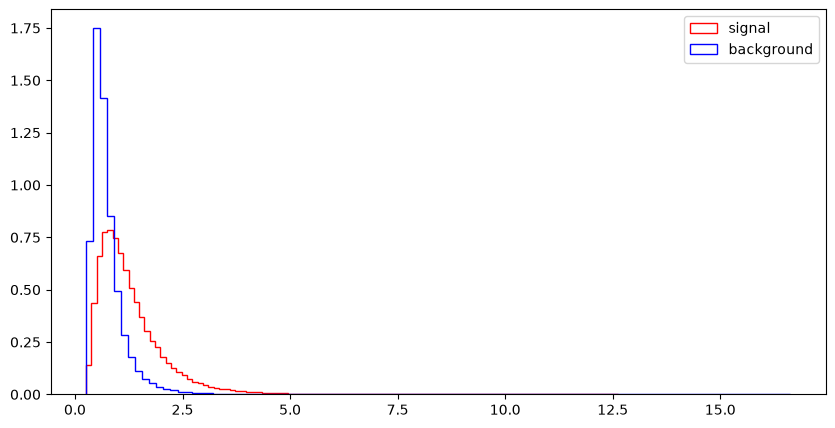

l_1_eta


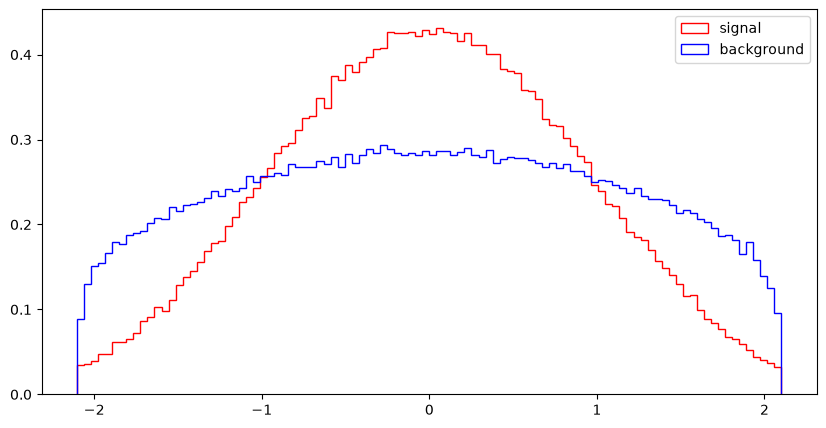

l_1_phi


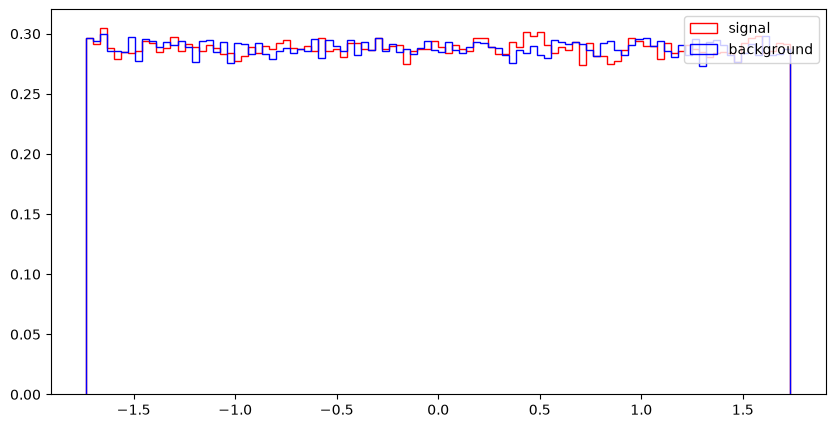

l_2_pT


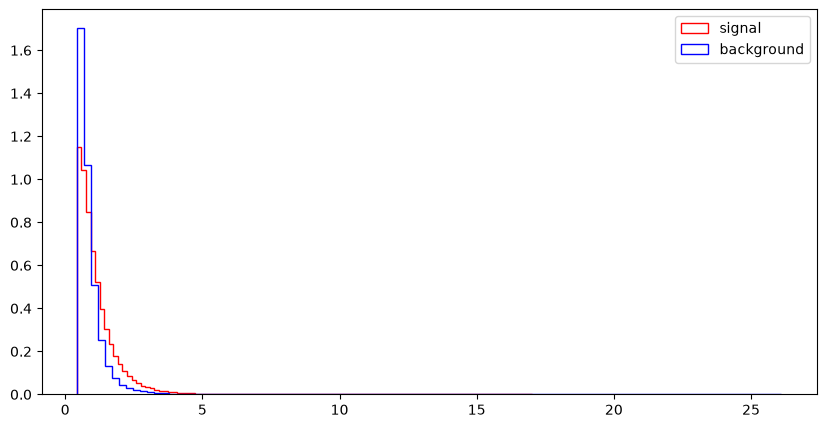

l_2_eta


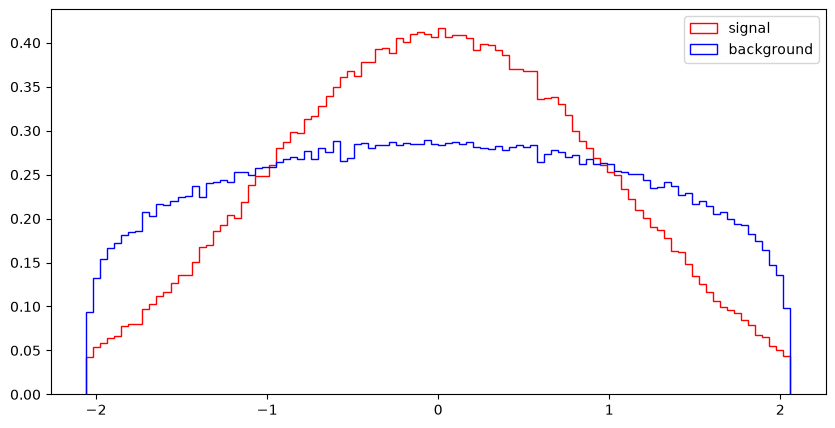

l_2_phi


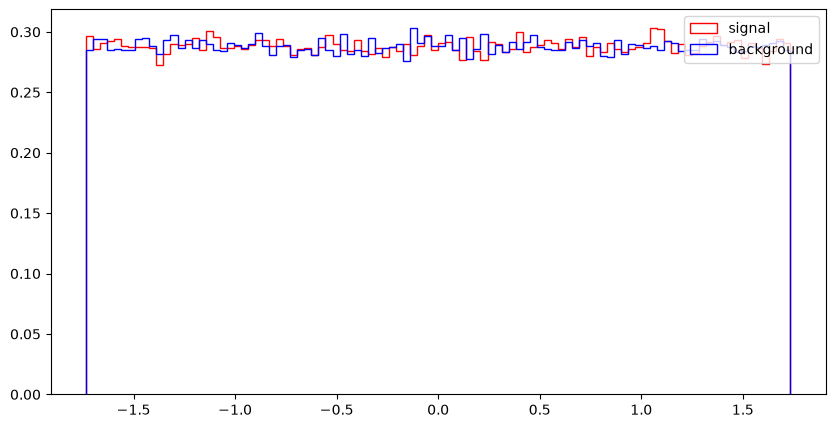

MET


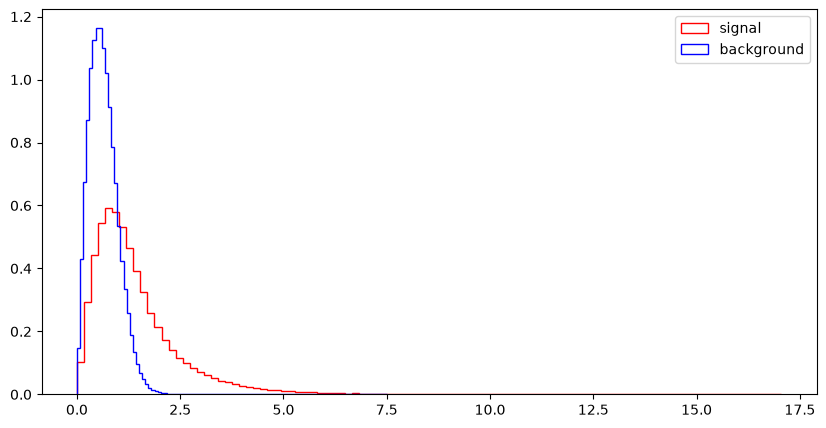

MET_phi


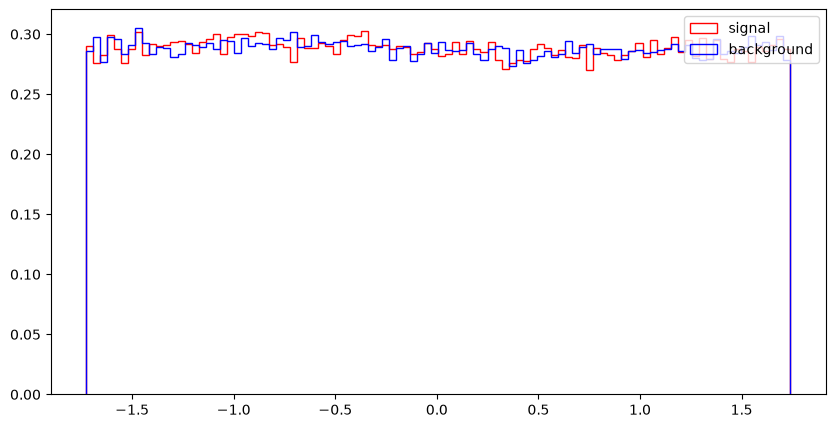

MET_rel


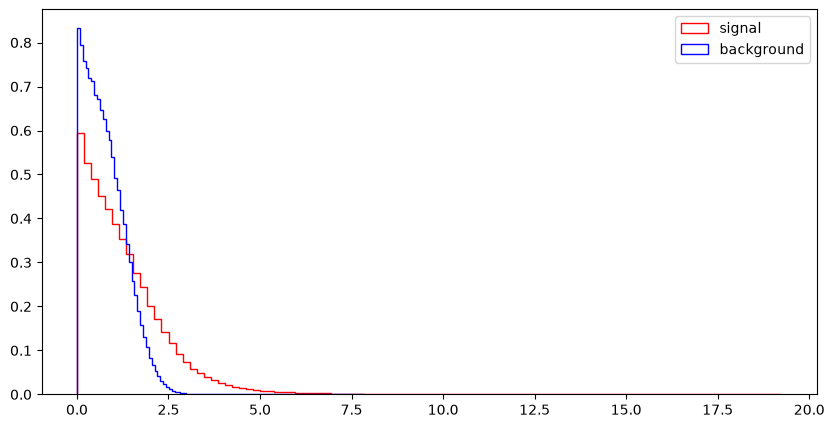

axial_MET


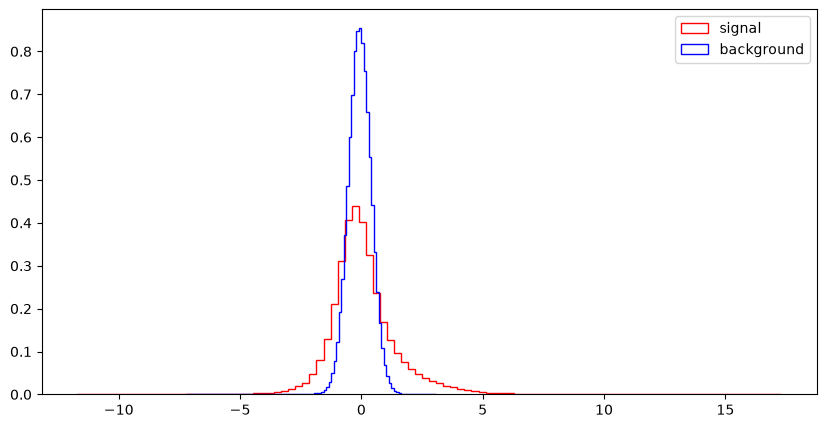

M_R


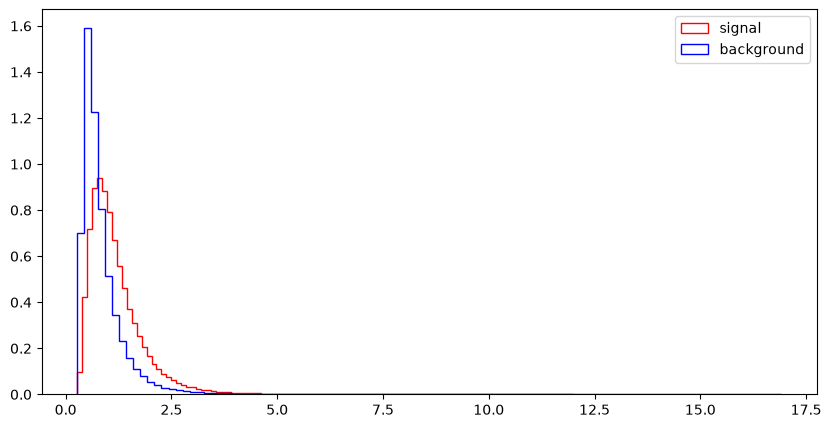

M_TR_2


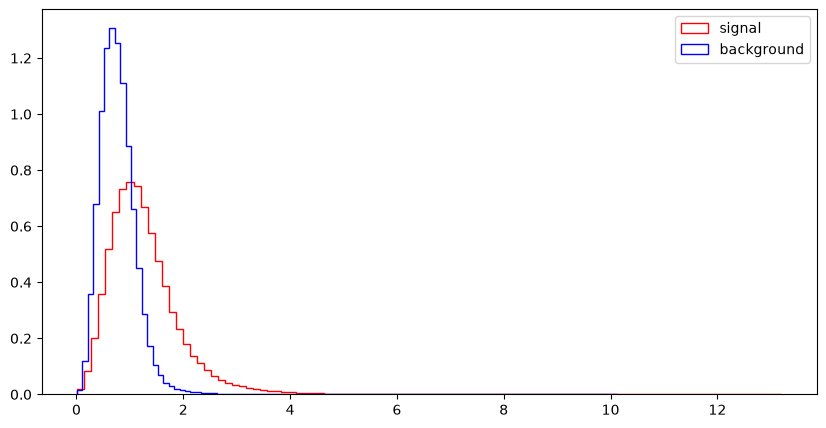

R


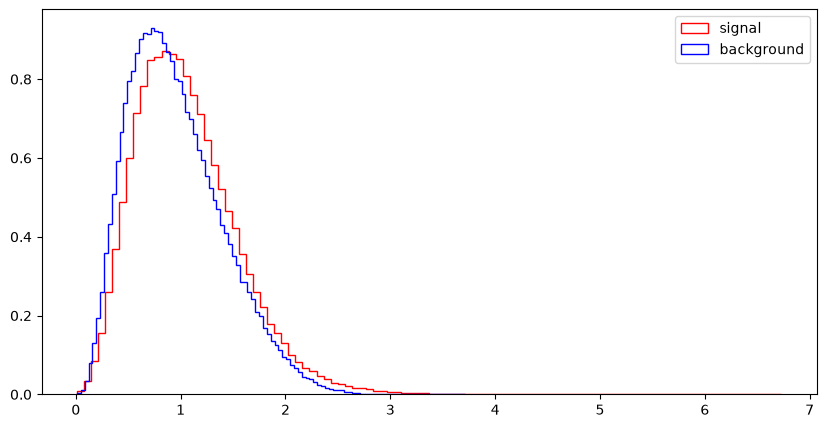

MT2


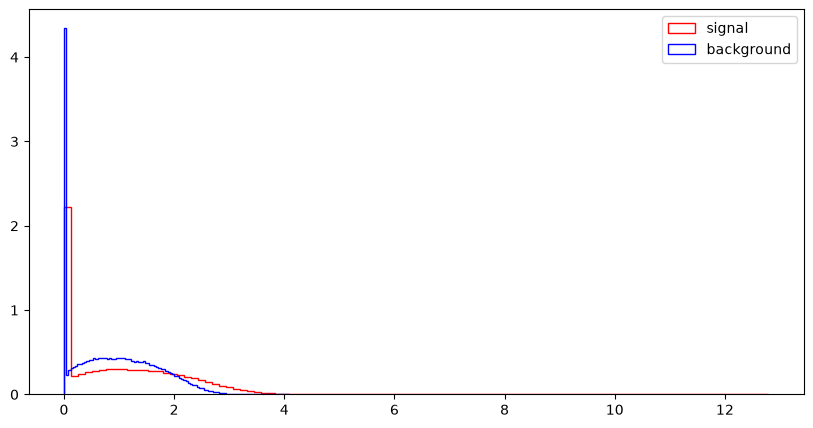

S_R


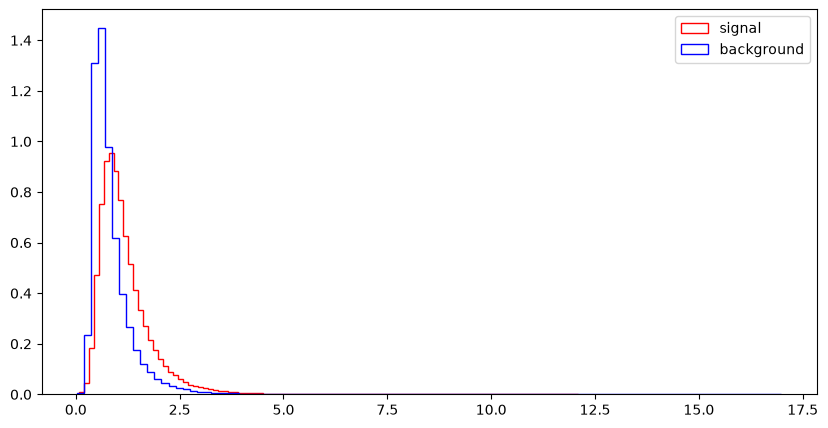

M_Delta_R


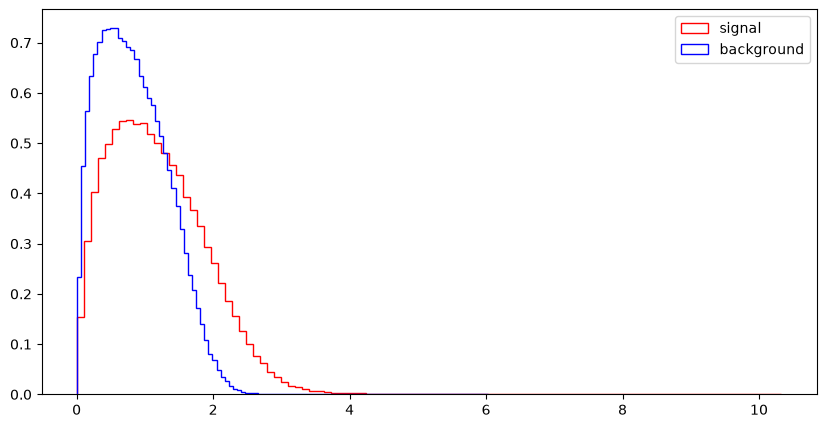

dPhi_r_b


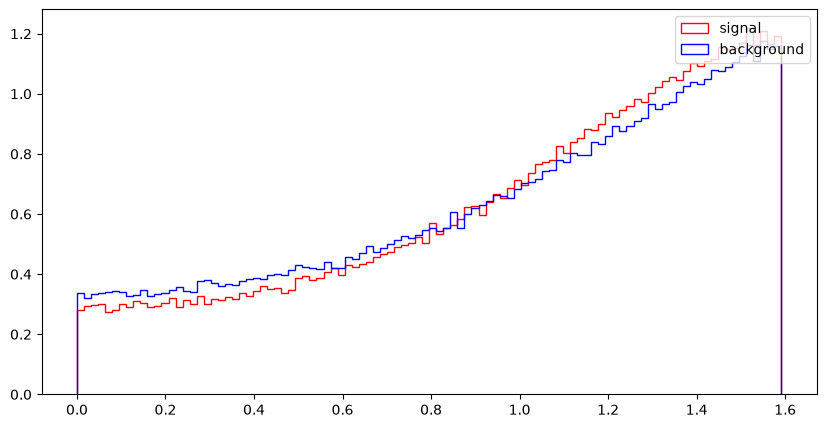

cos_theta_r1


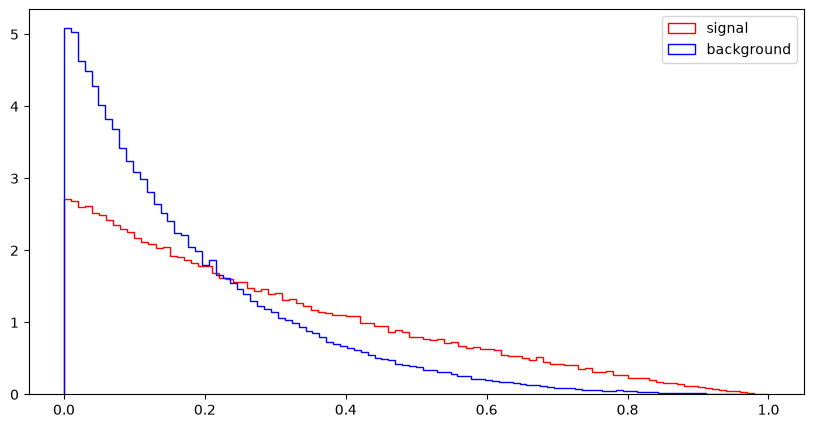

In [25]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

In [26]:
# Low-level features (first 8 variables after signal)
low_features = VarNames[1:9]

# High-level features (remaining 10 variables)
high_features = VarNames[9:19]

def plot_features(features, title):
    fig, axes = plt.subplots(
        2, 5, figsize=(18, 7)
    )
    axes = axes.flatten()

    for i, var in enumerate(features):
        ax = axes[i]

        signal = df_sig[var].dropna()
        background = df_bkg[var].dropna()

        # Use a common range for both distributions
        combined = df[var].dropna()
        xmin, xmax = combined.quantile([0.01, 0.99])

        bins = np.linspace(xmin, xmax, 51)

        ax.hist(
            signal, bins=bins, density=True,
            histtype="step", color="red",
            linewidth=1.5, label="Signal"
        )

        ax.hist(
            background, bins=bins, density=True,
            histtype="step", color="blue",
            linewidth=1.5, label="Background"
        )

        ax.set_title(var)
        ax.set_xlabel(var)
        ax.set_ylabel("Normalized frequency")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)

    for j in range(len(features), len(axes)):
        axes[j].axis("off")

    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

In [27]:
df_sig = df[df["signal"] == 1]
df_bkg = df[df["signal"] == 0]

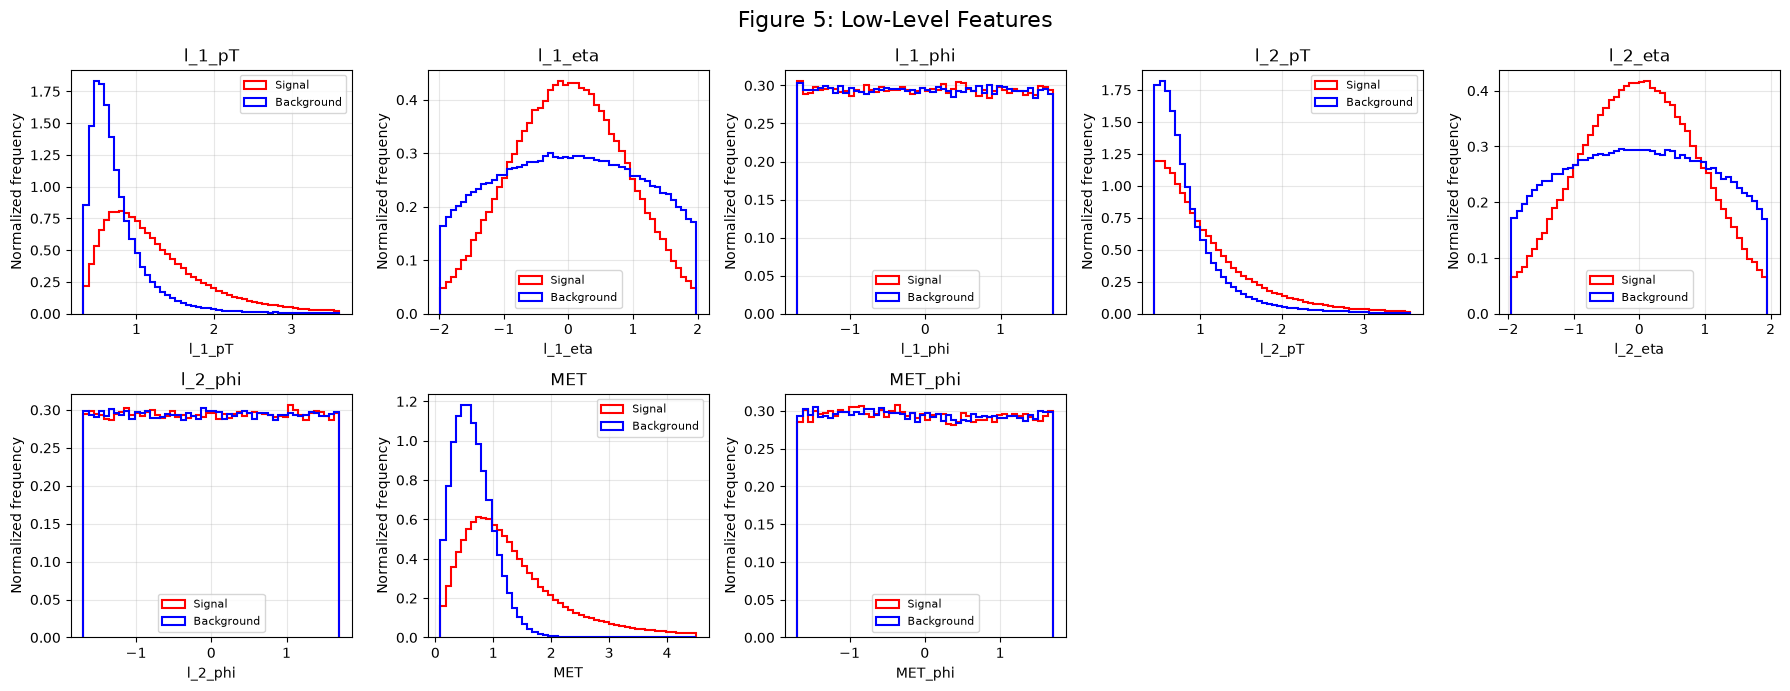

In [28]:
plot_features(low_features, "Figure 5: Low-Level Features")

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

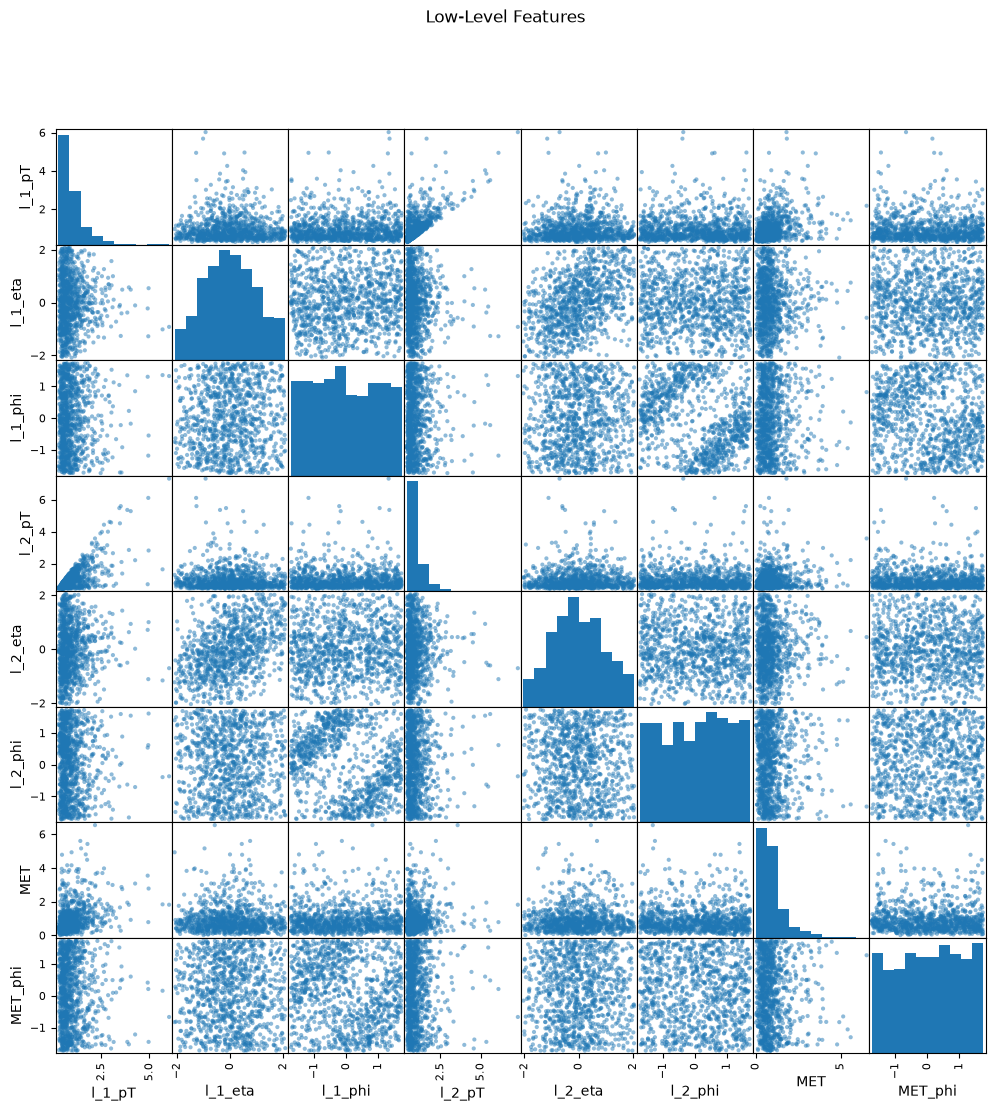

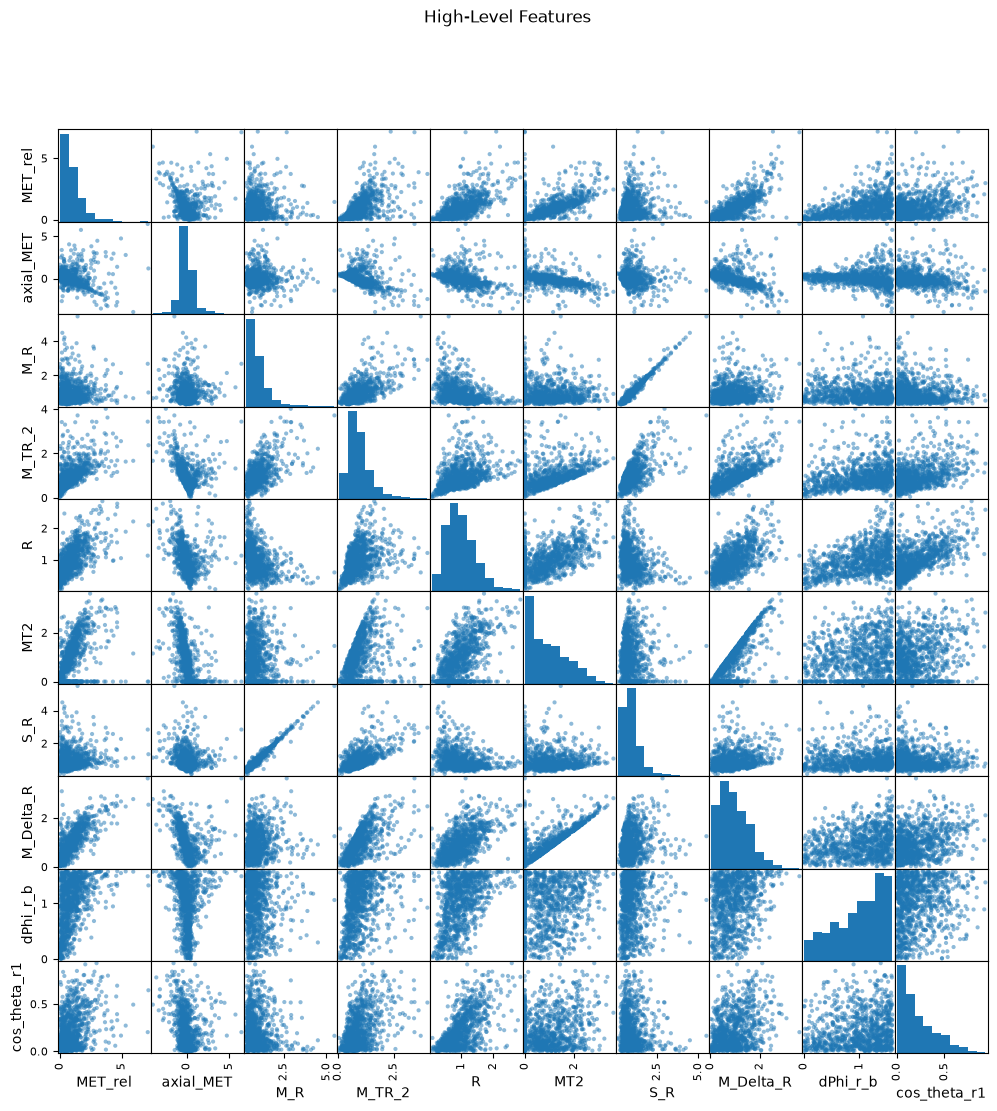

In [29]:
#part a
#Take smaller sample so the plots run faster
sample = df.sample(1000, random_state=42)

#Low-level features
pd.plotting.scatter_matrix(
    sample[low_features],
    figsize=(12, 12),
    diagonal="hist"
)

plt.suptitle("Low-Level Features")
plt.show()

pd.plotting.scatter_matrix(
    sample[high_features],
    figsize=(12, 12),
    diagonal="hist"
)

plt.suptitle("High-Level Features")
plt.show()

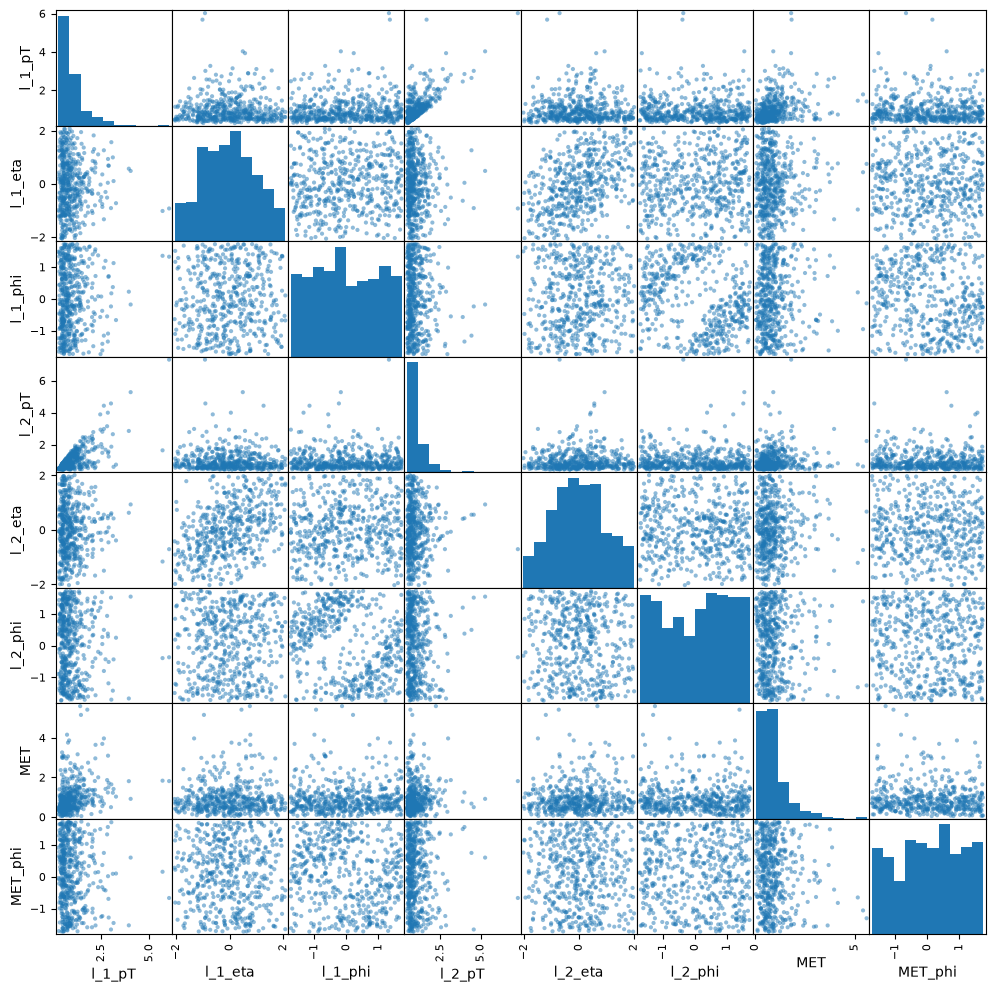

In [30]:
#part b
#Use fewer rows to make plotting faster
small_sample = df.sample(500, random_state=42)

pd.plotting.scatter_matrix(
    small_sample[low_features],
    figsize=(12, 12),
    diagonal="hist"
)

plt.show()

In [31]:
#part c
#Find correlations with signal
correlations = df.corr()["signal"]

#Sort from strongest to weakest
correlations = correlations.drop("signal")
correlations = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

print(correlations)

MET             0.439725
M_TR_2          0.425832
l_1_pT          0.391075
MET_rel         0.283162
M_Delta_R       0.274235
M_R             0.270347
cos_theta_r1    0.266836
S_R             0.261762
l_2_pT          0.196651
R               0.109128
MT2             0.079766
axial_MET       0.079145
dPhi_r_b        0.032801
l_2_eta         0.001426
MET_phi        -0.000590
l_1_phi         0.000433
l_1_eta         0.000425
l_2_phi         0.000339
Name: signal, dtype: float64


### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

In [33]:
#part b
from tabulate import tabulate

#Define low level and high level features
low_features = VarNames[1:9]
high_features = VarNames[9:19]
all_features = low_features + high_features

#Covariance matrices
cov_all = np.cov(df[all_features], rowvar=False)
cov_low = np.cov(df[low_features], rowvar=False)
cov_high = np.cov(df[high_features], rowvar=False)

#Correlation matrices
corr_all = np.corrcoef(df[all_features], rowvar=False)
corr_low = np.corrcoef(df[low_features], rowvar=False)
corr_high = np.corrcoef(df[high_features], rowvar=False)

In [36]:
#part c
from IPython.display import HTML, display
import tabulate

#Covariance matrix
print("Covariance Matrix - All Features")
display(HTML(tabulate.tabulate(
    cov_all,
    tablefmt="html",
    headers=all_features,
    showindex=all_features,
    floatfmt=".3f"
)))

#Correlation matrix
print("Correlation Matrix - All Features")
display(HTML(tabulate.tabulate(
    corr_all,
    tablefmt="html",
    headers=all_features,
    showindex=all_features,
    floatfmt=".3f"
)))

Covariance Matrix - All Features


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000,0.000,0.305,-0.000,0.001,0.228,-0.001,0.098,-0.010,0.364,0.287,-0.060,-0.012,0.343,0.098,-0.047,0.022
l_1_eta,-0.000,1.004,-0.001,-0.000,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,0.000,0.000,-0.001,-0.001,-0.001,0.000
l_1_phi,0.000,-0.001,1.004,0.001,0.000,-0.267,0.001,-0.185,0.001,-0.002,0.001,0.001,0.000,0.001,0.001,0.001,0.001,0.000
l_2_pT,0.305,-0.000,0.001,0.425,-0.001,0.000,0.079,-0.002,-0.001,0.051,0.325,0.163,-0.099,-0.069,0.322,0.006,-0.004,-0.028
l_2_eta,-0.000,0.408,0.000,-0.001,1.006,0.000,0.000,-0.000,0.001,-0.001,-0.001,0.000,0.000,0.001,-0.001,0.001,-0.000,0.000
l_2_phi,0.001,-0.001,-0.267,0.000,0.000,1.004,-0.000,-0.035,0.001,-0.002,0.001,0.001,0.001,0.002,0.001,0.001,-0.000,0.000
MET,0.228,-0.002,0.001,0.079,0.000,-0.000,0.762,-0.003,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.073
MET_phi,-0.001,-0.001,-0.185,-0.002,-0.000,-0.035,-0.003,1.003,-0.005,-0.000,-0.001,-0.001,-0.000,0.000,-0.002,-0.001,-0.002,0.000
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.790,-0.120,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.010,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0.000,-0.120,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054


Correlation Matrix - All Features


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1.000,-0.001,0.000,0.684,-0.001,0.001,0.383,-0.001,0.160,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1.000,-0.001,-0.000,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0.000,-0.001,-0.002,-0.002,0.002
l_1_phi,0.000,-0.001,1.000,0.002,0.000,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0.000,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0.000,0.002,1.000,-0.001,0.000,0.140,-0.002,-0.001,0.078,0.797,0.430,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0.000,-0.001,1.000,0.000,0.000,-0.000,0.001,-0.001,-0.001,0.000,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0.000,0.000,1.000,-0.000,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0.000
MET,0.383,-0.002,0.001,0.140,0.000,-0.000,1.000,-0.003,0.704,0.176,0.264,0.720,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0.000,-0.035,-0.003,1.000,-0.005,-0.000,-0.002,-0.002,-0.000,0.000,-0.003,-0.001,-0.004,0.001
MET_rel,0.160,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1.000,-0.134,0.078,0.584,0.595,0.535,0.150,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0.000,-0.134,1.000,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272


In [39]:
#part d
def make_tables(data, features):

    cov = np.cov(data[features], rowvar=False)
    corr = np.corrcoef(data[features], rowvar=False)

    print("Covariance Matrix")
    display(HTML(tabulate.tabulate(
        cov, tablefmt="html",
        headers=features, showindex=features,
        floatfmt=".3f"
    )))

    print("Correlation Matrix")
    display(HTML(tabulate.tabulate(
        corr, tablefmt="html",
        headers=features, showindex=features,
        floatfmt=".3f"
    )))


make_tables(df, all_features)
make_tables(df, low_features)
make_tables(df, high_features)

Covariance Matrix


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000,0.000,0.305,-0.000,0.001,0.228,-0.001,0.098,-0.010,0.364,0.287,-0.060,-0.012,0.343,0.098,-0.047,0.022
l_1_eta,-0.000,1.004,-0.001,-0.000,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,0.000,0.000,-0.001,-0.001,-0.001,0.000
l_1_phi,0.000,-0.001,1.004,0.001,0.000,-0.267,0.001,-0.185,0.001,-0.002,0.001,0.001,0.000,0.001,0.001,0.001,0.001,0.000
l_2_pT,0.305,-0.000,0.001,0.425,-0.001,0.000,0.079,-0.002,-0.001,0.051,0.325,0.163,-0.099,-0.069,0.322,0.006,-0.004,-0.028
l_2_eta,-0.000,0.408,0.000,-0.001,1.006,0.000,0.000,-0.000,0.001,-0.001,-0.001,0.000,0.000,0.001,-0.001,0.001,-0.000,0.000
l_2_phi,0.001,-0.001,-0.267,0.000,0.000,1.004,-0.000,-0.035,0.001,-0.002,0.001,0.001,0.001,0.002,0.001,0.001,-0.000,0.000
MET,0.228,-0.002,0.001,0.079,0.000,-0.000,0.762,-0.003,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.073
MET_phi,-0.001,-0.001,-0.185,-0.002,-0.000,-0.035,-0.003,1.003,-0.005,-0.000,-0.001,-0.001,-0.000,0.000,-0.002,-0.001,-0.002,0.000
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.790,-0.120,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.010,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0.000,-0.120,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054


Correlation Matrix


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1.000,-0.001,0.000,0.684,-0.001,0.001,0.383,-0.001,0.160,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1.000,-0.001,-0.000,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0.000,-0.001,-0.002,-0.002,0.002
l_1_phi,0.000,-0.001,1.000,0.002,0.000,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0.000,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0.000,0.002,1.000,-0.001,0.000,0.140,-0.002,-0.001,0.078,0.797,0.430,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0.000,-0.001,1.000,0.000,0.000,-0.000,0.001,-0.001,-0.001,0.000,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0.000,0.000,1.000,-0.000,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0.000
MET,0.383,-0.002,0.001,0.140,0.000,-0.000,1.000,-0.003,0.704,0.176,0.264,0.720,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0.000,-0.035,-0.003,1.000,-0.005,-0.000,-0.002,-0.002,-0.000,0.000,-0.003,-0.001,-0.004,0.001
MET_rel,0.160,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1.000,-0.134,0.078,0.584,0.595,0.535,0.150,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0.000,-0.134,1.000,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272


Covariance Matrix


...

,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1.000,-0.001,0.000,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1.000,-0.001,-0.000,0.406,-0.001,-0.002,-0.001
l_1_phi,0.000,-0.001,1.000,0.002,0.000,-0.266,0.001,-0.184
l_2_pT,0.684,-0.000,0.002,1.000,-0.001,0.000,0.140,-0.002
l_2_eta,-0.001,0.406,0.000,-0.001,1.000,0.000,0.000,-0.000
l_2_phi,0.001,-0.001,-0.266,0.000,0.000,1.000,-0.000,-0.035
MET,0.383,-0.002,0.001,0.140,0.000,-0.000,1.000,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0.000,-0.035,-0.003,1.000


Covariance Matrix


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.790,-0.120,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.120,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054
M_R,0.044,0.017,0.392,0.210,-0.113,-0.037,0.380,0.074,-0.029,-0.014
M_TR_2,0.302,-0.185,0.210,0.338,0.104,0.189,0.228,0.242,0.058,0.052
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.083,0.165,0.087,0.058
MT2,0.409,-0.461,-0.037,0.189,0.232,0.738,-0.011,0.433,0.021,0.045
S_R,0.082,-0.041,0.380,0.228,-0.083,-0.011,0.382,0.096,-0.003,-0.010
M_Delta_R,0.415,-0.233,0.074,0.242,0.165,0.433,0.096,0.389,0.042,0.039
dPhi_r_b,0.146,-0.025,-0.029,0.058,0.087,0.021,-0.003,0.042,0.190,0.009
cos_theta_r1,0.055,-0.054,-0.014,0.052,0.058,0.045,-0.010,0.039,0.009,0.039


Correlation Matrix


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1.000,-0.134,0.078,0.584,0.595,0.535,0.150,0.748,0.378,0.316
axial_MET,-0.134,1.000,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272
M_R,0.078,0.027,1.000,0.577,-0.383,-0.068,0.981,0.189,-0.106,-0.116
M_TR_2,0.584,-0.317,0.577,1.000,0.380,0.379,0.635,0.668,0.229,0.451
R,0.595,-0.383,-0.383,0.380,1.000,0.574,-0.287,0.564,0.424,0.627
MT2,0.535,-0.535,-0.068,0.379,0.574,1.000,-0.021,0.809,0.056,0.264
S_R,0.150,-0.067,0.981,0.635,-0.287,-0.021,1.000,0.249,-0.013,-0.085
M_Delta_R,0.748,-0.373,0.189,0.668,0.564,0.809,0.249,1.000,0.155,0.319
dPhi_r_b,0.378,-0.057,-0.106,0.229,0.424,0.056,-0.013,0.155,1.000,0.106
cos_theta_r1,0.316,-0.272,-0.116,0.451,0.627,0.264,-0.085,0.319,0.106,1.000


Hint: Example code for embedding a `tabulate` table into a notebook:

In [40]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

In [42]:
#Exercise 5.1

features = VarNames[1:19]

signal = df[df["signal"] == 1]
background = df[df["signal"] == 0]

cuts = {}

for feature in features:
    if signal[feature].mean() > background[feature].mean():
        cuts[feature] = 1
    else:
        cuts[feature] = 2

    print(feature, cuts[feature])

l_1_pT 1
l_1_eta 1
l_1_phi 1
l_2_pT 1
l_2_eta 1
l_2_phi 1
MET 1
MET_phi 2
MET_rel 1
axial_MET 1
M_R 1
M_TR_2 1
R 1
MT2 1
S_R 1
M_Delta_R 1
dPhi_r_b 1
cos_theta_r1 1


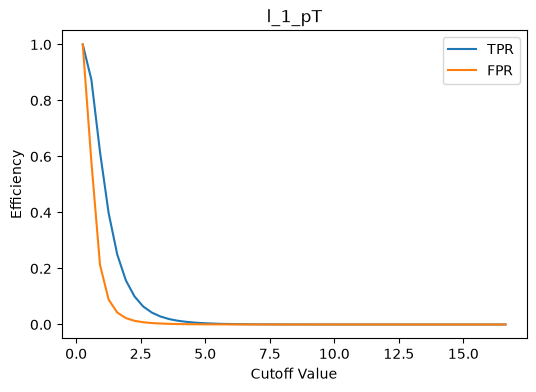

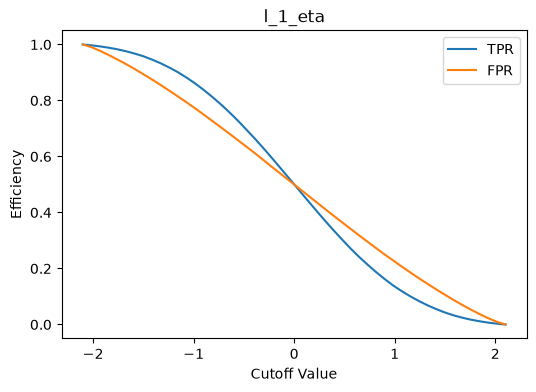

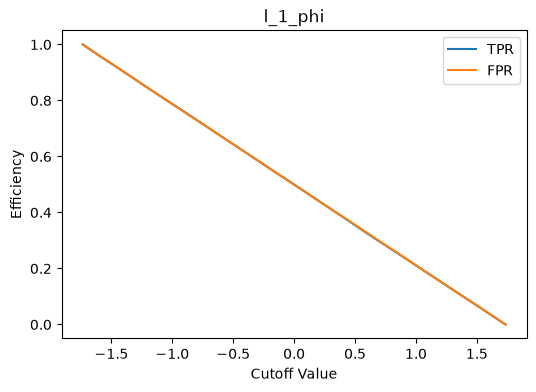

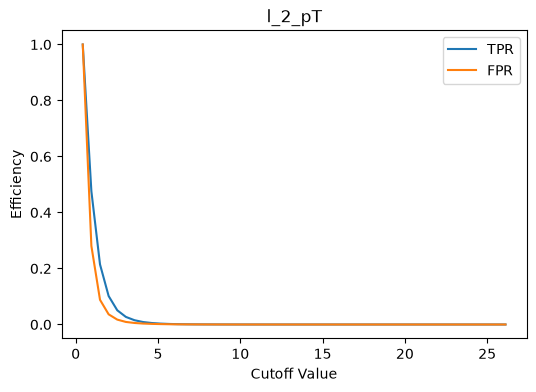

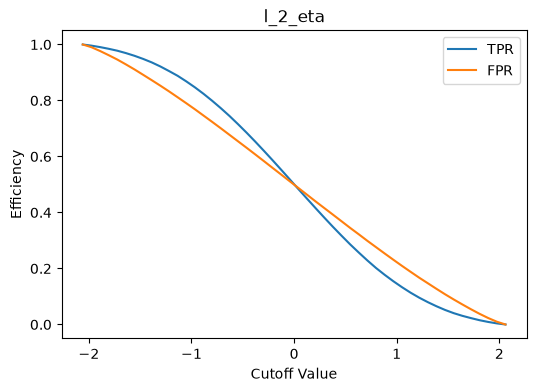

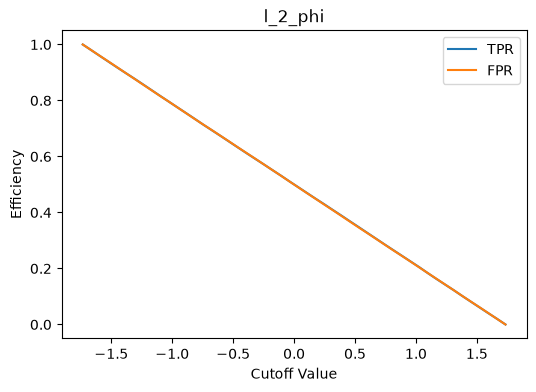

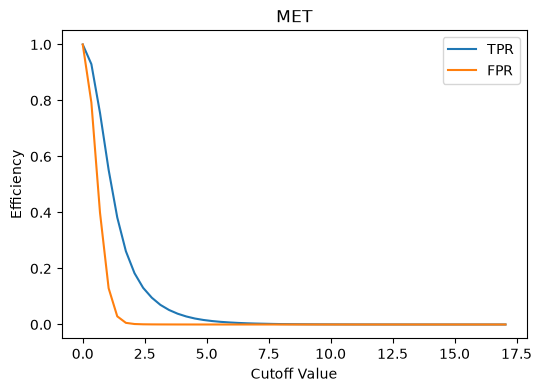

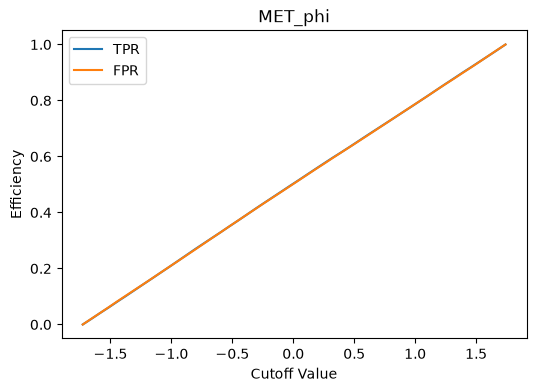

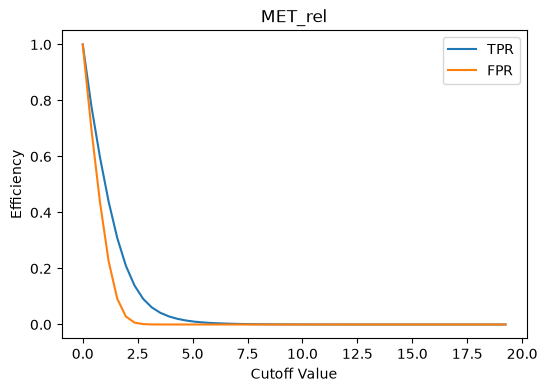

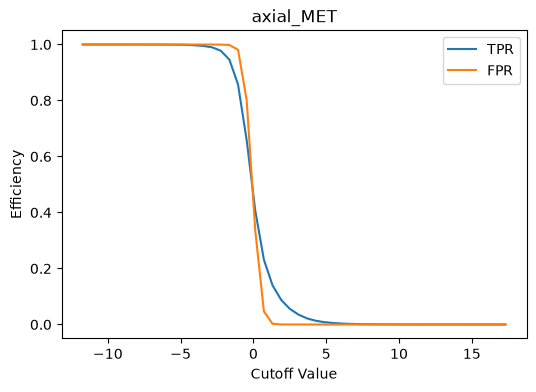

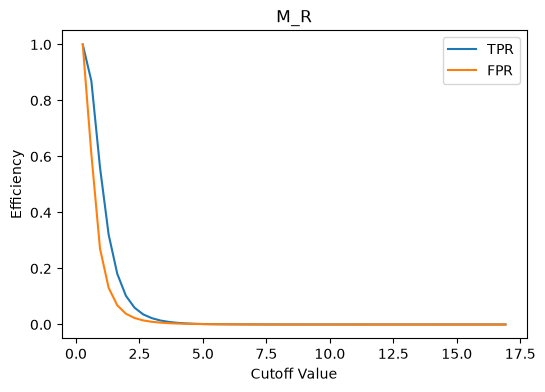

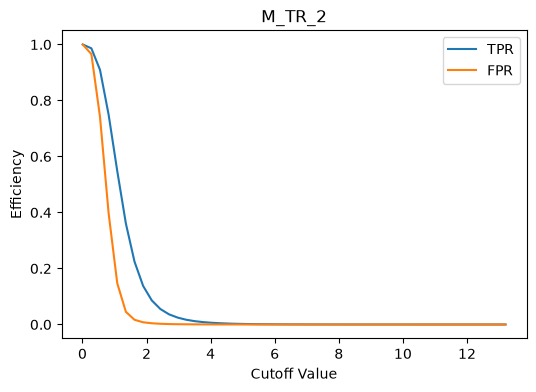

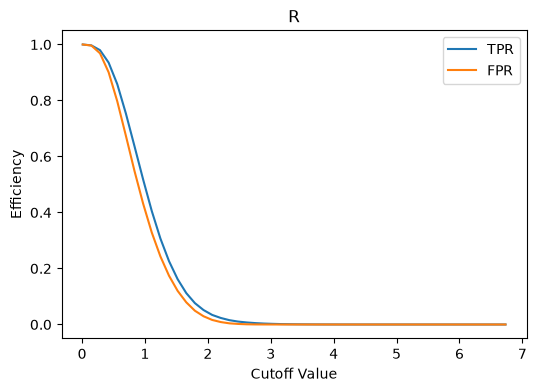

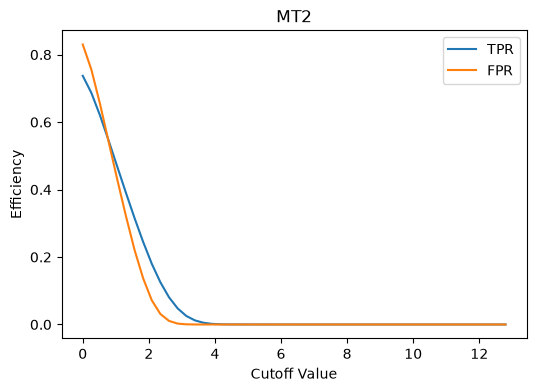

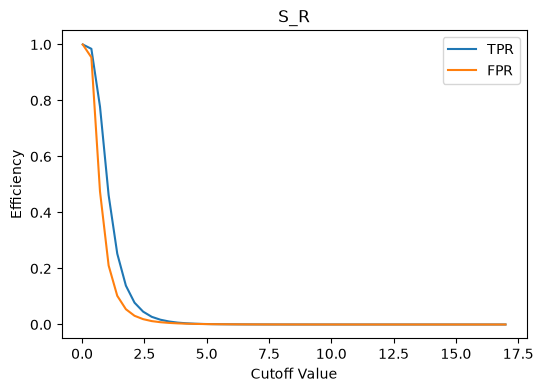

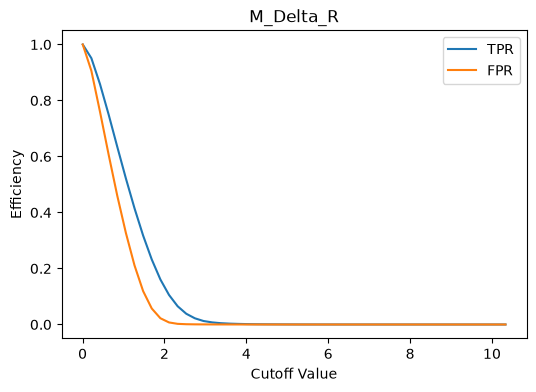

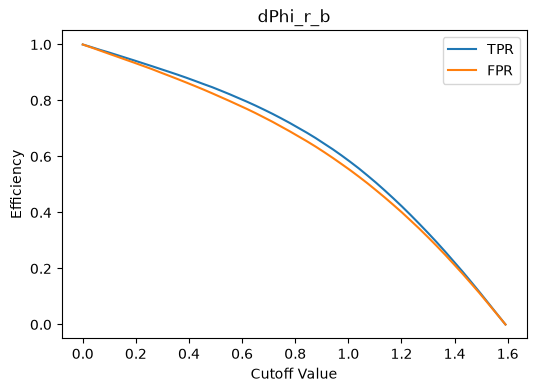

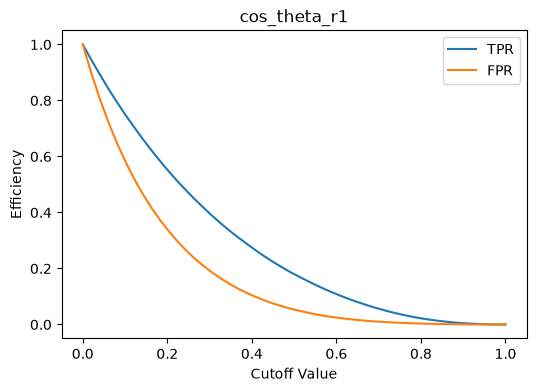

In [44]:
#Exercise 5.2

#Apply the selection rule
def select_values(values, rule, xc, mu):

    if rule == 1:
        return values > xc
    elif rule == 2:
        return values < xc
    elif rule == 3:
        return abs(values - mu) > xc
    else:
        return abs(values - mu) < xc


results = {}

for feature in features:
    rule = cuts[feature]
    mu = df[feature].mean()

    if rule == 3 or rule == 4:
        values = abs(df[feature] - mu)
    else:
        values = df[feature]

    thresholds = np.linspace(values.min(), values.max(), 50)

    tpr = []
    fpr = []

    for xc in thresholds:
        sig_pass = select_values(signal[feature], rule, xc, mu)
        bkg_pass = select_values(background[feature], rule, xc, mu)

        tpr.append(sig_pass.mean())
        fpr.append(bkg_pass.mean())

    results[feature] = (thresholds, tpr, fpr)

    plt.figure(figsize=(6, 4))
    plt.plot(thresholds, tpr, label="TPR")
    plt.plot(thresholds, fpr, label="FPR")

    plt.title(feature)
    plt.xlabel("Cutoff Value")
    plt.ylabel("Efficiency")
    plt.legend()
    plt.show()

l_1_pT 10 100
Best cutoff: 0.924
Significance: 1.176
l_1_pT 100 1000
Best cutoff: 0.924
Significance: 3.719
l_1_pT 1000 10000
Best cutoff: 0.924
Significance: 11.759
l_1_pT 10000 100000
Best cutoff: 0.924
Significance: 37.187


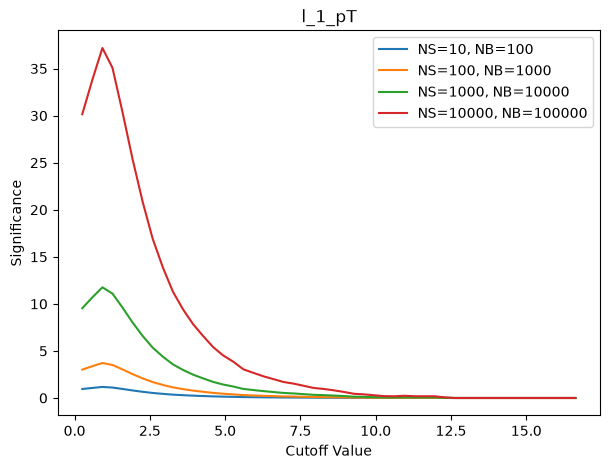

l_1_eta 10 100
Best cutoff: -1.502
Significance: 0.963
l_1_eta 100 1000
Best cutoff: -1.502
Significance: 3.046
l_1_eta 1000 10000
Best cutoff: -1.502
Significance: 9.631
l_1_eta 10000 100000
Best cutoff: -1.502
Significance: 30.456


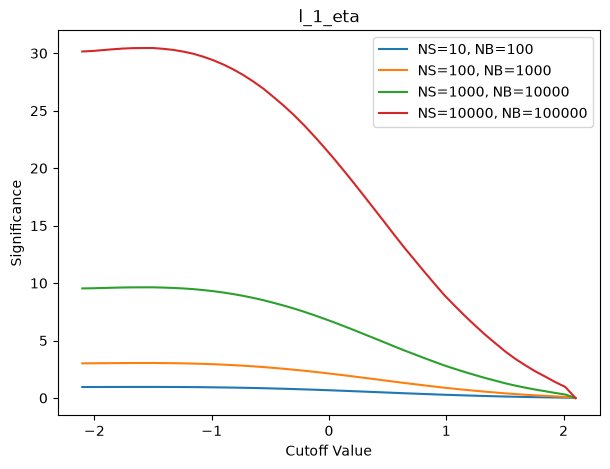

l_1_phi 10 100
Best cutoff: -1.735
Significance: 0.953
l_1_phi 100 1000
Best cutoff: -1.735
Significance: 3.015
l_1_phi 1000 10000
Best cutoff: -1.735
Significance: 9.535
l_1_phi 10000 100000
Best cutoff: -1.735
Significance: 30.151


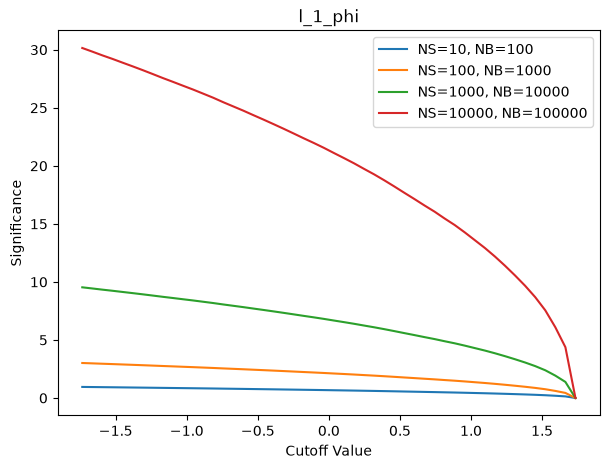

l_2_pT 10 100
Best cutoff: 0.429
Significance: 0.953
l_2_pT 100 1000
Best cutoff: 0.429
Significance: 3.015
l_2_pT 1000 10000
Best cutoff: 0.429
Significance: 9.535
l_2_pT 10000 100000
Best cutoff: 0.429
Significance: 30.151


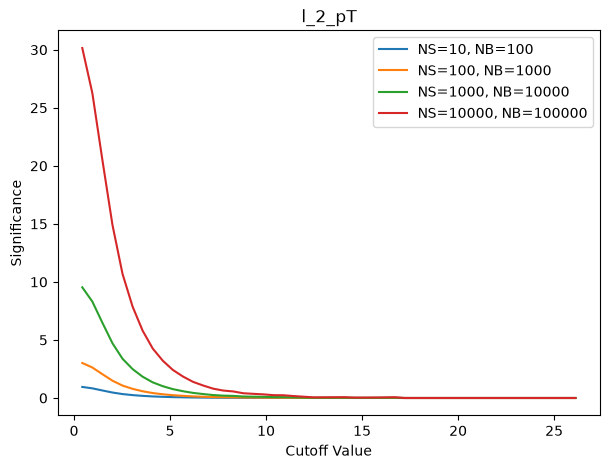

l_2_eta 10 100
Best cutoff: -1.639
Significance: 0.957
l_2_eta 100 1000
Best cutoff: -1.639
Significance: 3.026
l_2_eta 1000 10000
Best cutoff: -1.639
Significance: 9.57
l_2_eta 10000 100000
Best cutoff: -1.639
Significance: 30.264


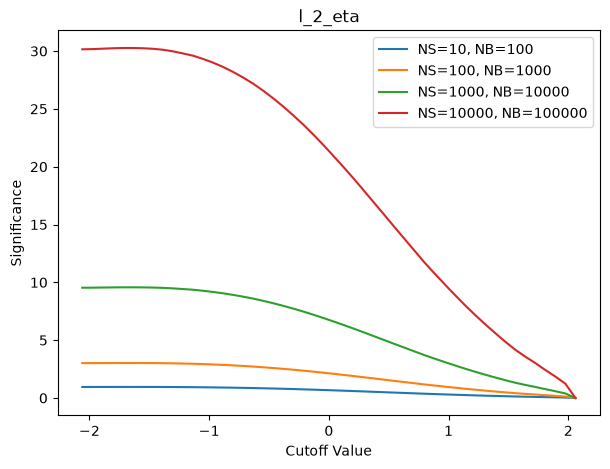

l_2_phi 10 100
Best cutoff: -1.734
Significance: 0.953
l_2_phi 100 1000
Best cutoff: -1.734
Significance: 3.015
l_2_phi 1000 10000
Best cutoff: -1.734
Significance: 9.535
l_2_phi 10000 100000
Best cutoff: -1.734
Significance: 30.151


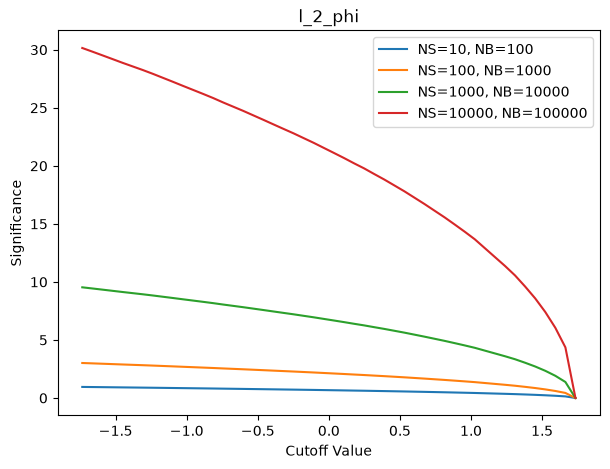

MET 10 100
Best cutoff: 1.393
Significance: 1.473
MET 100 1000
Best cutoff: 1.393
Significance: 4.657
MET 1000 10000
Best cutoff: 1.393
Significance: 14.728
MET 10000 100000
Best cutoff: 1.393
Significance: 46.574


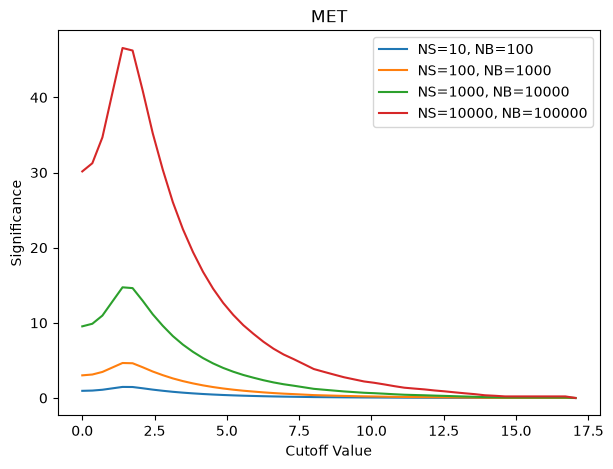

MET_phi 10 100
Best cutoff: 1.741
Significance: 0.953
MET_phi 100 1000
Best cutoff: 1.741
Significance: 3.015
MET_phi 1000 10000
Best cutoff: 1.741
Significance: 9.535
MET_phi 10000 100000
Best cutoff: 1.741
Significance: 30.151


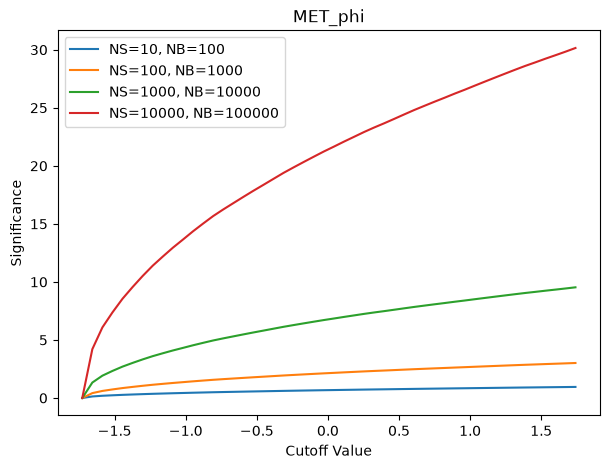

MET_rel 10 100
Best cutoff: 2.356
Significance: 0.97
MET_rel 100 1000
Best cutoff: 2.356
Significance: 3.066
MET_rel 1000 10000
Best cutoff: 2.356
Significance: 9.696
MET_rel 10000 100000
Best cutoff: 2.356
Significance: 30.66


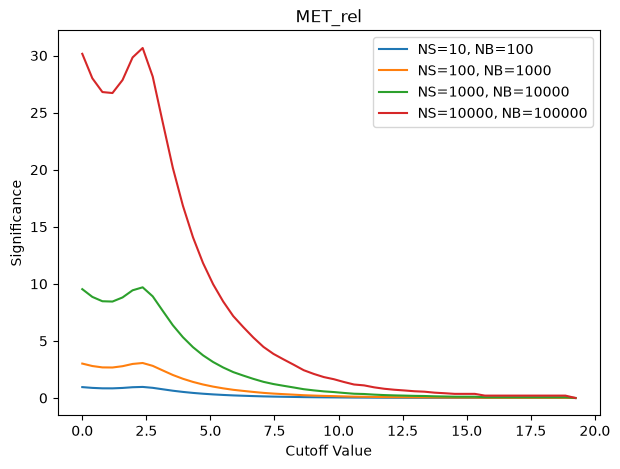

axial_MET 10 100
Best cutoff: 1.314
Significance: 1.091
axial_MET 100 1000
Best cutoff: 1.314
Significance: 3.452
axial_MET 1000 10000
Best cutoff: 1.314
Significance: 10.915
axial_MET 10000 100000
Best cutoff: 1.314
Significance: 34.515


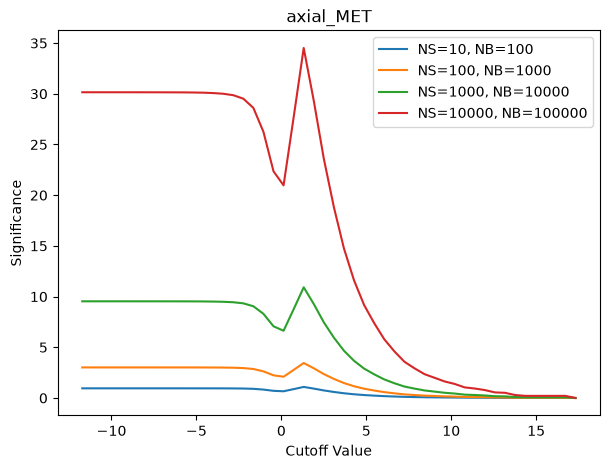

M_R 10 100
Best cutoff: 0.607
Significance: 1.043
M_R 100 1000
Best cutoff: 0.607
Significance: 3.298
M_R 1000 10000
Best cutoff: 0.607
Significance: 10.431
M_R 10000 100000
Best cutoff: 0.607
Significance: 32.984


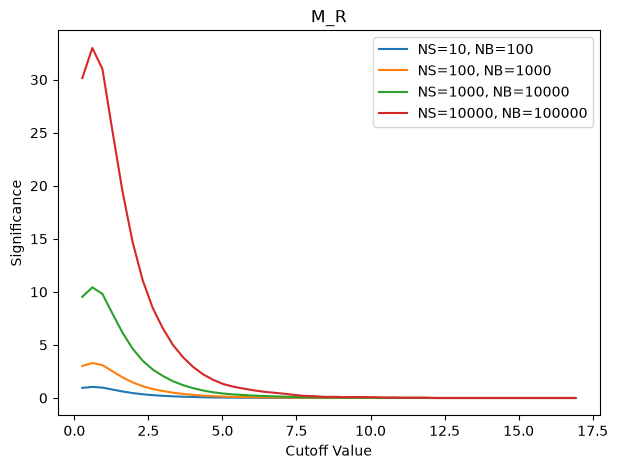

M_TR_2 10 100
Best cutoff: 1.356
Significance: 1.265
M_TR_2 100 1000
Best cutoff: 1.356
Significance: 4.0
M_TR_2 1000 10000
Best cutoff: 1.356
Significance: 12.649
M_TR_2 10000 100000
Best cutoff: 1.356
Significance: 40.001


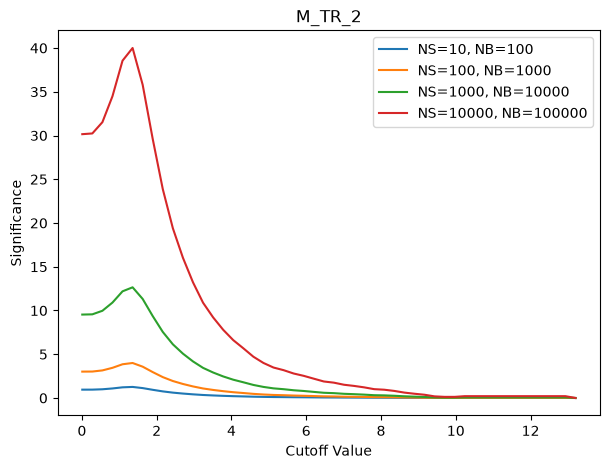

R 10 100
Best cutoff: 0.011
Significance: 0.953
R 100 1000
Best cutoff: 0.011
Significance: 3.015
R 1000 10000
Best cutoff: 0.011
Significance: 9.535
R 10000 100000
Best cutoff: 0.011
Significance: 30.151


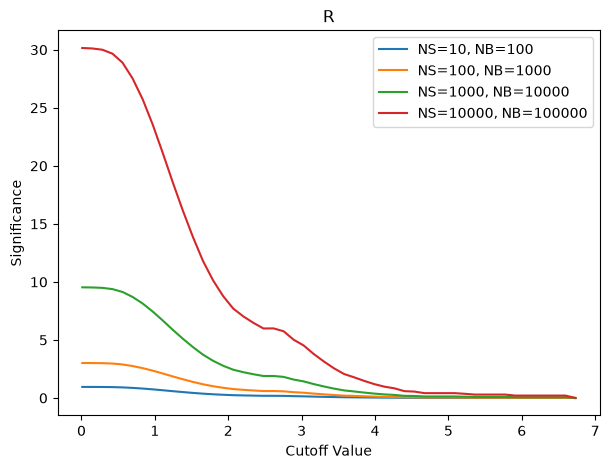

MT2 10 100
Best cutoff: 0.0
Significance: 0.776
MT2 100 1000
Best cutoff: 0.0
Significance: 2.452
MT2 1000 10000
Best cutoff: 0.0
Significance: 7.755
MT2 10000 100000
Best cutoff: 0.0
Significance: 24.525


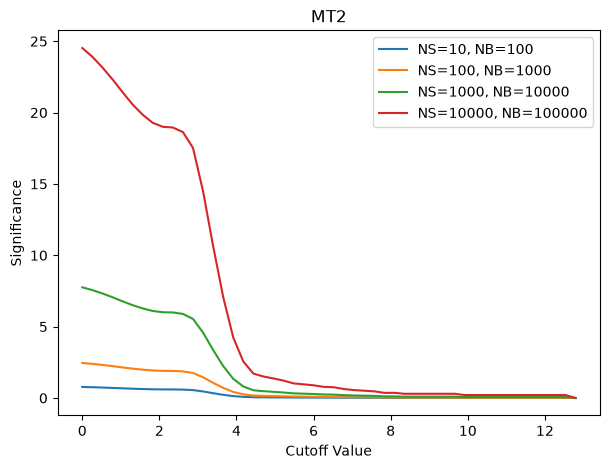

S_R 10 100
Best cutoff: 0.72
Significance: 1.046
S_R 100 1000
Best cutoff: 0.72
Significance: 3.309
S_R 1000 10000
Best cutoff: 0.72
Significance: 10.464
S_R 10000 100000
Best cutoff: 0.72
Significance: 33.09


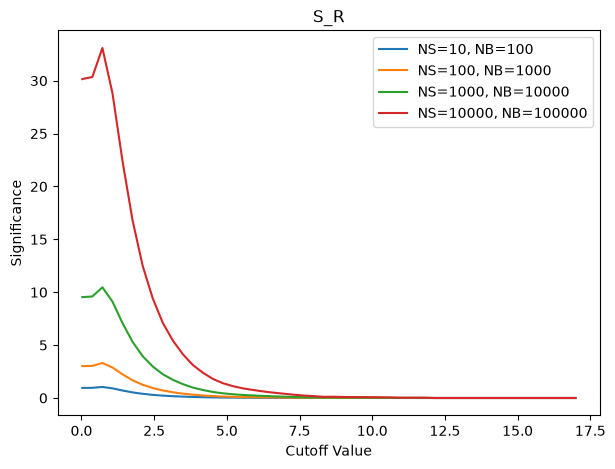

M_Delta_R 10 100
Best cutoff: 0.004
Significance: 0.953
M_Delta_R 100 1000
Best cutoff: 0.004
Significance: 3.015
M_Delta_R 1000 10000
Best cutoff: 0.004
Significance: 9.535
M_Delta_R 10000 100000
Best cutoff: 0.004
Significance: 30.151


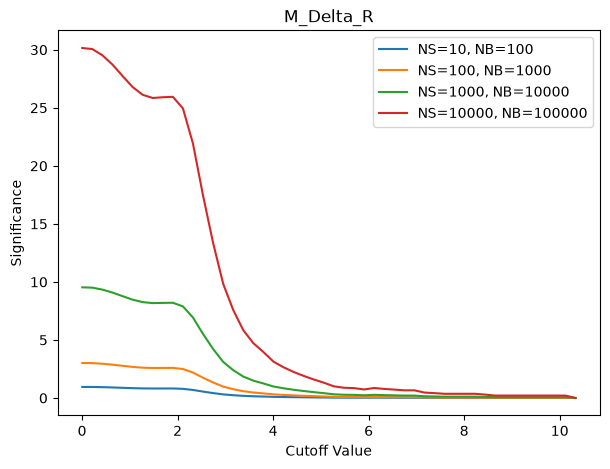

dPhi_r_b 10 100
Best cutoff: 0.0
Significance: 0.953
dPhi_r_b 100 1000
Best cutoff: 0.0
Significance: 3.015
dPhi_r_b 1000 10000
Best cutoff: 0.0
Significance: 9.535
dPhi_r_b 10000 100000
Best cutoff: 0.0
Significance: 30.151


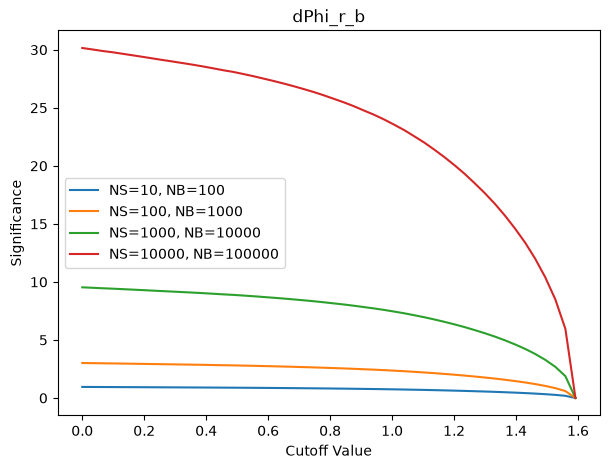

cos_theta_r1 10 100
Best cutoff: 0.0
Significance: 0.953
cos_theta_r1 100 1000
Best cutoff: 0.0
Significance: 3.015
cos_theta_r1 1000 10000
Best cutoff: 0.0
Significance: 9.535
cos_theta_r1 10000 100000
Best cutoff: 0.0
Significance: 30.151


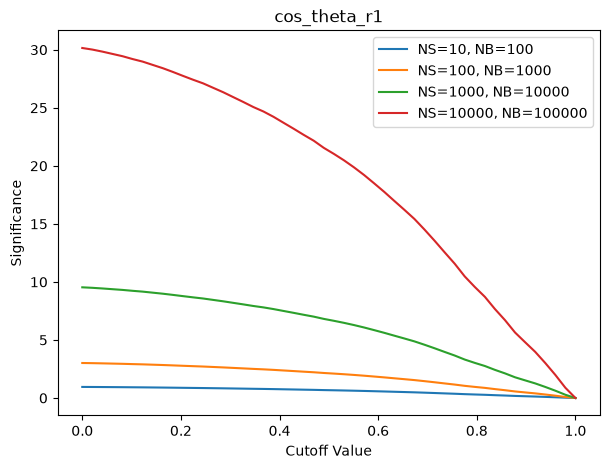

In [45]:
#Exercise 5.3

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

for feature in features:
    thresholds, tpr, fpr = results[feature]

    tpr = np.array(tpr)
    fpr = np.array(fpr)

    plt.figure(figsize=(7, 5))

    for ns, nb in scenarios:
        new_s = tpr * ns
        new_b = fpr * nb

        #Calculate significance
        total = new_s + new_b
        significance = np.zeros(len(total))

        for i in range(len(total)):
            if total[i] > 0:
                significance[i] = new_s[i] / np.sqrt(total[i])

        plt.plot(thresholds, significance,
                 label=f"NS={ns}, NB={nb}")

        best = np.argmax(significance)

        print(feature, ns, nb)
        print("Best cutoff:", round(thresholds[best], 3))
        print("Significance:", round(significance[best], 3))

    plt.title(feature)
    plt.xlabel("Cutoff Value")
    plt.ylabel("Significance")
    plt.legend()
    plt.show()

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [46]:
#Exercise 6.1

scores = {}

for feature in features:
    thresholds, tpr, fpr = results[feature]

    tpr = np.array(tpr)
    fpr = np.array(fpr)

    ns = 100
    nb = 1000

    s = ns * tpr
    b = nb * fpr

    significance = np.zeros(len(s))

    for i in range(len(s)):
        if s[i] + b[i] > 0:
            significance[i] = s[i] / np.sqrt(s[i] + b[i])

    scores[feature] = max(significance)

#Find top 3 features
top3 = sorted(scores, key=scores.get, reverse=True)[:3]

print("Selected features:", top3)

Selected features: ['MET', 'M_TR_2', 'l_1_pT']


In [48]:
#Exercise 6.2

scenarios = [(10, 100), (100, 1000),
             (1000, 10000), (10000, 100000)]

def cut_flow(data, selected, ns, nb):
    current = data.copy()
    table = []

    for feature in selected:
        thresholds, tpr, fpr = results[feature]

        tpr = np.array(tpr)
        fpr = np.array(fpr)

        s = ns * tpr
        b = nb * fpr

        sig = np.zeros(len(s))

        for i in range(len(s)):
            if s[i] + b[i] > 0:
                sig[i] = s[i] / np.sqrt(s[i] + b[i])

        best = np.argmax(sig)
        xc = thresholds[best]

        rule = cuts[feature]
        mu = df[feature].mean()

        current = current[
            select_values(current[feature], rule, xc, mu)
        ]

        eps_s = (current["signal"] == 1).sum() / (data["signal"] == 1).sum()
        eps_b = (current["signal"] == 0).sum() / (data["signal"] == 0).sum()

        new_s = ns * eps_s
        new_b = nb * eps_b

        significance = 0
        if new_s + new_b > 0:
            significance = new_s / np.sqrt(new_s + new_b)

        table.append([feature, round(xc, 3),
                      round(eps_s, 3), round(eps_b, 3),
                      round(new_s, 3), round(new_b, 3),
                      round(significance, 3)])

    return pd.DataFrame(
        table,
        columns=["Feature", "Cutoff", "eps_S", "eps_B",
                 "N_S", "N_B", "Significance"]
    )


for ns, nb in scenarios:
    print("Scenario:", ns, nb)
    display(cut_flow(df, top3, ns, nb))

Scenario: 10 100


,Feature,Cutoff,eps_S,eps_B,N_S,N_B,Significance
0,MET,1.393,0.382,0.029,3.823,2.915,1.473
1,M_TR_2,1.356,0.260,0.016,2.596,1.623,1.264
2,l_1_pT,0.924,0.219,0.012,2.191,1.203,1.189


Scenario: 100 1000


,Feature,Cutoff,eps_S,eps_B,N_S,N_B,Significance
0,MET,1.393,0.382,0.029,38.230,29.148,4.657
1,M_TR_2,1.356,0.260,0.016,25.960,16.232,3.997
2,l_1_pT,0.924,0.219,0.012,21.905,12.029,3.760


Scenario: 1000 10000


,Feature,Cutoff,eps_S,eps_B,N_S,N_B,Significance
0,MET,1.393,0.382,0.029,382.303,291.481,14.728
1,M_TR_2,1.356,0.260,0.016,259.604,162.324,12.638
2,l_1_pT,0.924,0.219,0.012,219.054,120.293,11.891


Scenario: 10000 100000


,Feature,Cutoff,eps_S,eps_B,N_S,N_B,Significance
0,MET,1.393,0.382,0.029,3823.028,2914.812,46.574
1,M_TR_2,1.356,0.260,0.016,2596.044,1623.239,39.966
2,l_1_pT,0.924,0.219,0.012,2190.539,1202.933,37.604


In [49]:
#Exercise 6.3

print("Correlation between selected features")
print(df[top3].corr().round(3))

def optimize_flow(data, selected, ns, nb):
    current = data.copy()

    for feature in selected:
        rule = cuts[feature]
        mu = df[feature].mean()
        thresholds = results[feature][0]

        best_sig = -1
        best_xc = thresholds[0]
        best_data = current

        for xc in thresholds:
            test = current[
                select_values(current[feature], rule, xc, mu)
            ]

            eps_s = (test["signal"] == 1).sum() / (data["signal"] == 1).sum()
            eps_b = (test["signal"] == 0).sum() / (data["signal"] == 0).sum()

            s = ns * eps_s
            b = nb * eps_b

            sig = 0
            if s + b > 0:
                sig = s / np.sqrt(s + b)

            if sig > best_sig:
                best_sig = sig
                best_xc = xc
                best_data = test

        current = best_data
        print(feature, "Cutoff:", round(best_xc, 3),
              "Significance:", round(best_sig, 3))

    return best_sig


print("First order")
sig1 = optimize_flow(df, top3[:2], 100, 1000)

print("Reverse order")
sig2 = optimize_flow(df, top3[:2][::-1], 100, 1000)

print("Final significance:")
print("First order:", round(sig1, 3))
print("Reverse order:", round(sig2, 3))

Correlation between selected features
          MET  M_TR_2  l_1_pT
MET     1.000   0.720   0.383
M_TR_2  0.720   1.000   0.723
l_1_pT  0.383   0.723   1.000
First order
MET Cutoff: 1.393 Significance: 4.657
M_TR_2 Cutoff: 0.01 Significance: 4.657
Reverse order
M_TR_2 Cutoff: 1.356 Significance: 4.0
MET Cutoff: 1.045 Significance: 4.021
Final significance:
First order: 4.657
Reverse order: 4.021


## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



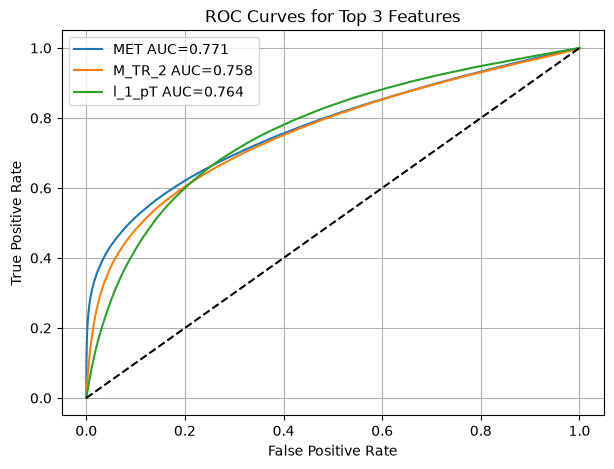

In [54]:
#Exercise 7.1

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(7, 5))

for feature in top3:
    y = df["signal"]

    if cuts[feature] == 1:
        scores = df[feature]
    elif cuts[feature] == 2:
        scores = -df[feature]
    elif cuts[feature] == 3:
        scores = abs(df[feature] - df[feature].mean())
    else:
        scores = -abs(df[feature] - df[feature].mean())

    fpr, tpr, thresholds = roc_curve(y, scores)
    area = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=feature + " AUC=" + str(round(area, 3)))

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Top 3 Features")
plt.legend()
plt.grid()
plt.show()

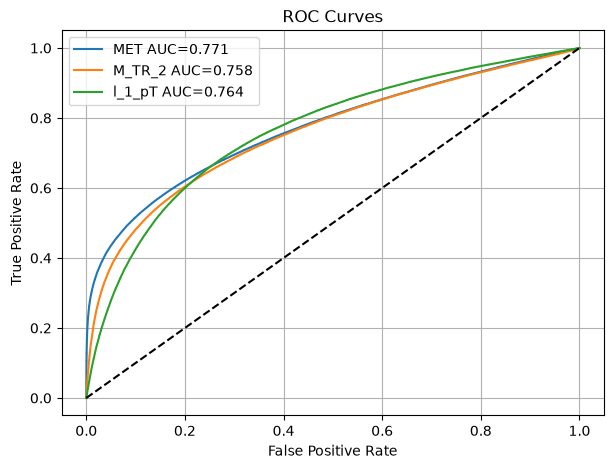

In [56]:
#Exercise 7.2

def plot_roc(data, features):

    plt.figure(figsize=(7, 5))

    for feature in features:
        y = data["signal"]

        if cuts[feature] == 1:
            scores = data[feature]
        elif cuts[feature] == 2:
            scores = -data[feature]
        elif cuts[feature] == 3:
            scores = abs(data[feature] - df[feature].mean())
        else:
            scores = -abs(data[feature] - df[feature].mean())

        fpr, tpr, thresholds = roc_curve(y, scores)
        area = auc(fpr, tpr)

        plt.plot(fpr, tpr,
                 label=feature + " AUC=" + str(round(area, 3)))

    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curves")
    plt.legend()
    plt.grid()
    plt.show()

plot_roc(df, top3)

Before selections


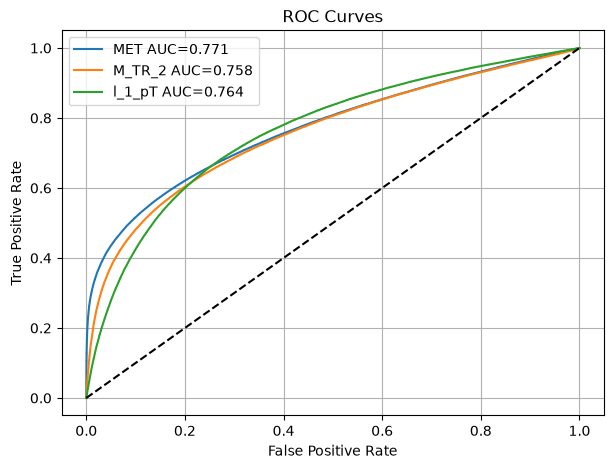

After selecting: MET


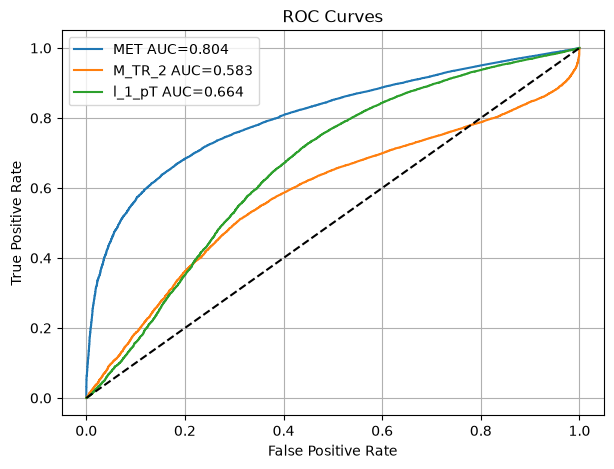

After selecting: M_TR_2


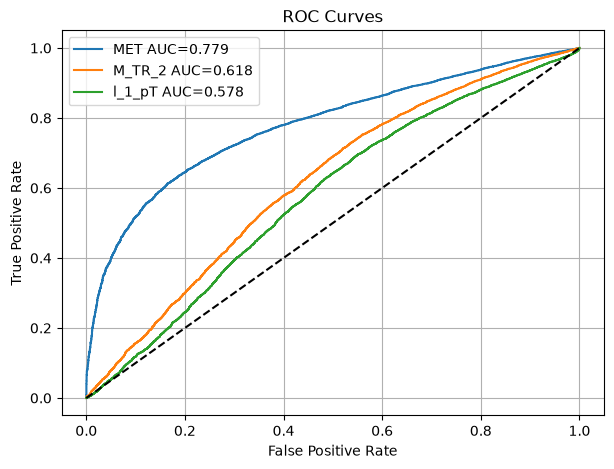

After selecting: l_1_pT


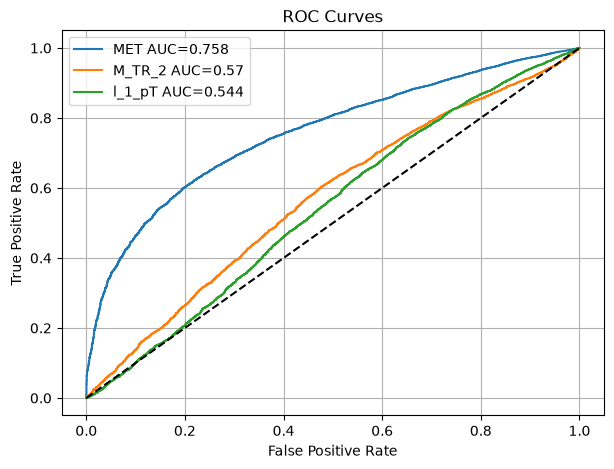

In [57]:
#Exercise 7.3

best_cuts = {}

for feature in top3:
    thresholds, tpr, fpr = results[feature]

    tpr = np.array(tpr)
    fpr = np.array(fpr)

    s = 100 * tpr
    b = 1000 * fpr

    significance = np.zeros(len(s))

    for i in range(len(s)):
        if s[i] + b[i] > 0:
            significance[i] = s[i] / np.sqrt(s[i] + b[i])

    best = np.argmax(significance)
    best_cuts[feature] = thresholds[best]

#Start with the original data
current = df.copy()

print("Before selections")
plot_roc(current, top3)

for feature in top3:
    xc = best_cuts[feature]
    rule = cuts[feature]
    mu = df[feature].mean()

    current = current[
        select_values(current[feature], rule, xc, mu)
    ]

    print("After selecting:", feature)

    if current["signal"].nunique() == 2:
        plot_roc(current, top3)
    else:
        print("Not enough classes to plot ROC")

Original order
After: MET


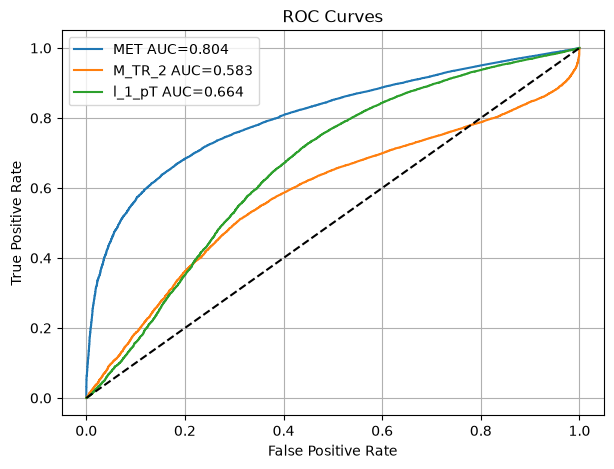

After: M_TR_2


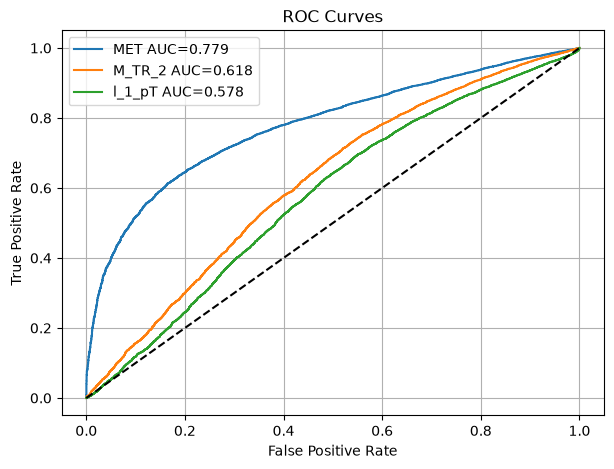

After: l_1_pT


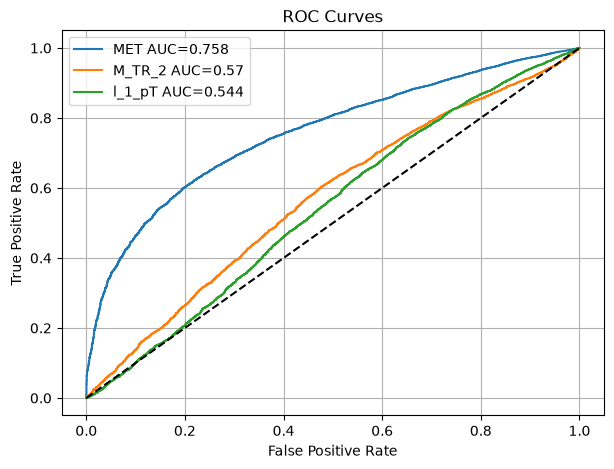

Reverse order
After: l_1_pT


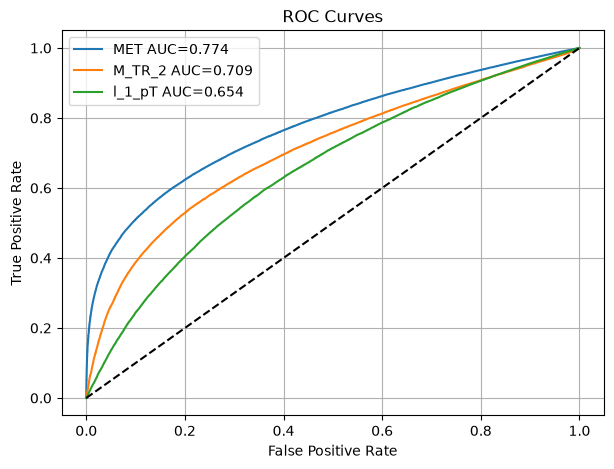

After: M_TR_2


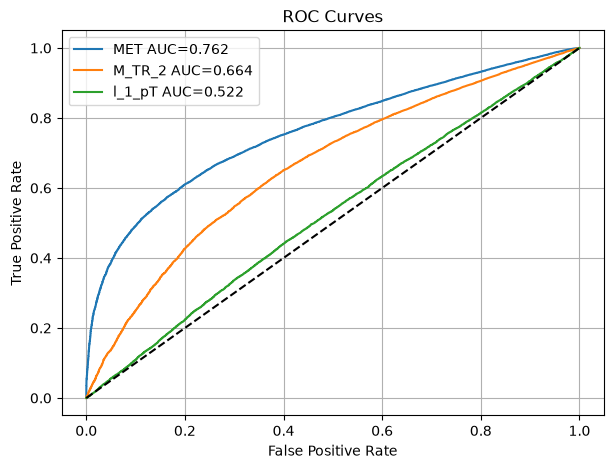

After: MET


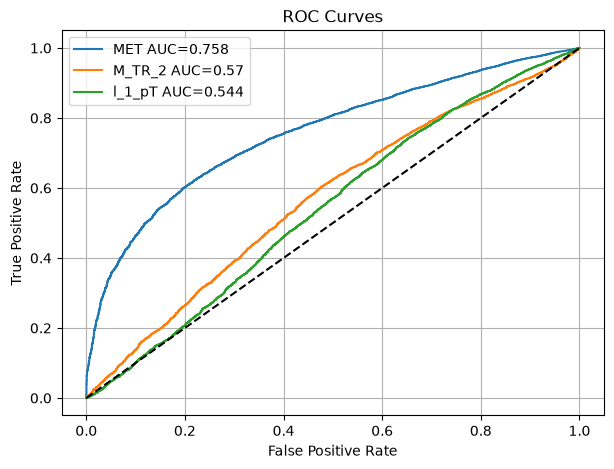

In [58]:
#Exercise 7.4

print("Original order")

current = df.copy()

for feature in top3:
    xc = best_cuts[feature]
    rule = cuts[feature]
    mu = df[feature].mean()

    current = current[
        select_values(current[feature], rule, xc, mu)
    ]

    print("After:", feature)

    if current["signal"].nunique() == 2:
        plot_roc(current, top3)


print("Reverse order")

current = df.copy()

for feature in top3[::-1]:
    xc = best_cuts[feature]
    rule = cuts[feature]
    mu = df[feature].mean()

    current = current[
        select_values(current[feature], rule, xc, mu)
    ]

    print("After:", feature)

    if current["signal"].nunique() == 2:
        plot_roc(current, top3)

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

In [61]:
#Exercise 8.1

# Separate signal and background
signal = df[df["signal"] == 1]
background = df[df["signal"] == 0]

#Use all 18 features
features = VarNames[1:19]

x1 = signal[features].to_numpy()
x2 = background[features].to_numpy()

#Find the mean of each group
m1 = x1.mean(axis=0)
m2 = x2.mean(axis=0)

#Between class matrix
diff = m2 - m1
SB = np.outer(diff, diff)

#Within class matrix
SW = np.cov(x1, rowvar=False) * (len(x1) - 1)
SW += np.cov(x2, rowvar=False) * (len(x2) - 1)

print("Between-class matrix:")
print(SB)

print("Within-class matrix:")
print(SW)


Between-class matrix:
[[ 2.87970231e-01  4.58922304e-04  4.67467434e-04  1.38148662e-01
   1.54068049e-03  3.66095560e-04  4.13461344e-01 -6.36618070e-04
   2.71136238e-01  8.54657090e-02  1.82331687e-01  2.66557653e-01
   5.53227373e-02  7.37824064e-02  1.74241790e-01  1.84116478e-01
   1.54056891e-02  5.66281031e-02]
 [ 4.58922304e-04  7.31359210e-07  7.44977113e-07  2.20159917e-04
   2.45529768e-06  5.83426339e-07  6.58910580e-04 -1.01454317e-06
   4.32094896e-04  1.36201995e-04  2.90571971e-04  4.24798257e-04
   8.81648006e-05  1.17582959e-04  2.77679548e-04  2.93416294e-04
   2.45511986e-05  9.02450903e-05]
 [ 4.67467434e-04  7.44977113e-07  7.58848582e-07  2.24259293e-04
   2.50101531e-06  5.94289733e-07  6.71179491e-04 -1.03343396e-06
   4.40140500e-04  1.38738075e-04  2.95982420e-04  4.32707998e-04
   8.98064286e-05  1.19772353e-04  2.82849940e-04  2.98879704e-04
   2.50083417e-05  9.19254533e-05]
 [ 1.38148662e-01  2.20159917e-04  2.24259293e-04  6.62743950e-02
   7.39114414e-

Linear coefficients:
[-2.26832982e-06 -5.63688439e-09 -2.10423856e-09 -9.95582982e-07
 -3.48452234e-09 -2.70762588e-09 -1.65185357e-06 -2.74241844e-09
 -1.39723282e-07 -2.64205675e-07  2.72149250e-07 -1.48465692e-07
  2.11167032e-06  3.24040633e-07  1.81173242e-06 -1.69348122e-06
  7.50902836e-08 -5.06860437e-06]


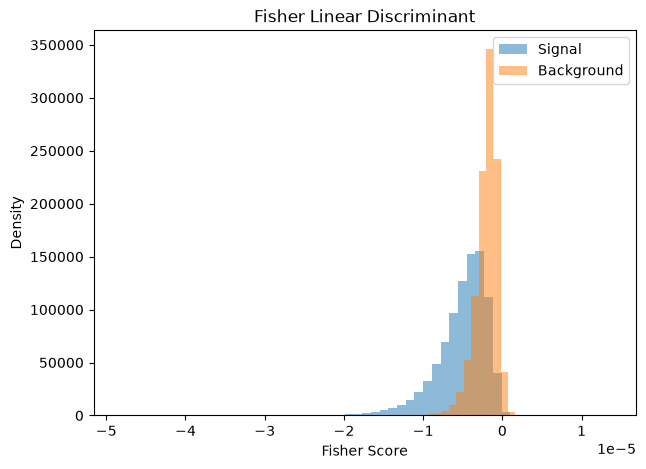

In [62]:
#Exercise 8.2

#Calculate linear coefficients
w = np.linalg.solve(SW, m2 - m1)

print("Linear coefficients:")
print(w)

#Calculate Fisher scores
F_signal = x1 @ w
F_background = x2 @ w

#Plot histograms
plt.figure(figsize=(7, 5))

plt.hist(F_signal, bins=50, density=True,
         alpha=0.5, label="Signal")

plt.hist(F_background, bins=50, density=True,
         alpha=0.5, label="Background")

plt.xlabel("Fisher Score")
plt.ylabel("Density")
plt.title("Fisher Linear Discriminant")
plt.legend()
plt.show()


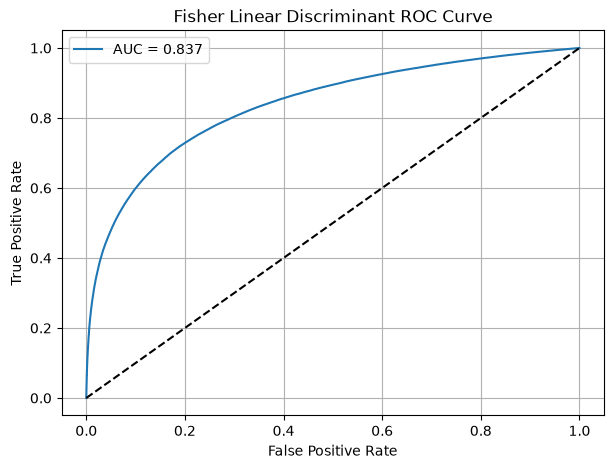

AUC: 0.837


In [64]:
#Exercise 8.3

#Calculate scores for all events
F = df[features].to_numpy() @ w

#Higher scores should represent signal
scores = -F

fpr, tpr, thresholds = roc_curve(df["signal"], scores)

area = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label="AUC = " + str(round(area, 3)))
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Fisher Linear Discriminant ROC Curve")
plt.legend()
plt.grid()
plt.show()

print("AUC:", round(area, 3))


In [65]:
#Exercise 8.4

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

for ns, nb in scenarios:
    new_s = ns * tpr
    new_b = nb * fpr

    significance = np.zeros(len(tpr))

    for i in range(len(tpr)):
        if new_s[i] + new_b[i] > 0:
            significance[i] = new_s[i] / np.sqrt(new_s[i] + new_b[i])

    best = np.argmax(significance)

    print("Scenario:", ns, nb)
    print("Maximum significance:", round(significance[best], 3))
    print("Best TPR:", round(tpr[best], 3))
    print("Best FPR:", round(fpr[best], 3))
    print()


Scenario: 10 100
Maximum significance: 1.533
Best TPR: 0.492
Best FPR: 0.054

Scenario: 100 1000
Maximum significance: 4.846
Best TPR: 0.492
Best FPR: 0.054

Scenario: 1000 10000
Maximum significance: 15.326
Best TPR: 0.492
Best FPR: 0.054

Scenario: 10000 100000
Maximum significance: 48.464
Best TPR: 0.492
Best FPR: 0.054

